# Customer Churn Prediction — End-to-End ML Notebook

**Retail bank, Kenya · 7,043 customers · binary classification with a 7% positive class**

This notebook follows the structure of *Lab 2 — Messy Data & Leakage-Safe Features* (**audit → clean → hunt the leak → leakage-safe pipeline**) and extends it into a complete modelling workflow: a locked hold-out, EDA, model comparison and tuning, calibration, a cost-based decision layer, explainability, fairness checks, and a deployable artefact.

| # | Section | Mirrors Lab 2 | What is enhanced / new |
|---|---|---|---|
| 0 | Setup & business framing | — | **New:** decision, cost assumptions, metric choice |
| 1 | Audit | Missingness, duplicates, validity | Validity-rule scorecard, *structural* missingness, constant & redundant columns |
| 2 | Clean & split | Canonical `customer_id` | Shared cleaning module, **hold-out locked before any EDA** |
| 3 | EDA | — | **New:** target balance, churn-rate profiles, univariate screen |
| 4 | Features | RFM / ratio features | Row-wise (stateless) features that live *inside* the pipeline |
| 5 | Hunt the leak | Correlation screen + lineage | Lineage table, hard vs. suspect leaks, provenance tests |
| 6 | Pipeline: honest vs. leaky | `ColumnTransformer` + group CV | PR-AUC for imbalance, **governance ablations** (demographics, service flags) |
| 7 | Model comparison & tuning | — | **New:** baselines, LR / RF / HGB, randomized search on PR-AUC |
| 8 | Calibration & final test | — | **New:** OOF calibration, one-shot test, bootstrap CIs, lift / gains |
| 9 | Decision layer | — | **New:** KES expected-value targeting, capacity policy, sensitivity |
| 10 | Explainability & fairness | — | **New:** permutation importance, odds ratios, PDP, subgroup audit |
| 11 | Persist, score, monitor | — | **New:** artefact, fresh-process scoring test, PSI drift check |
| 12 | Conclusions | Step-4 gap comment | Findings, limitations, next steps |

**To run:** put `BCustomer_Churn.csv` next to this notebook and run top to bottom (about 3–6 minutes). Requires Python ≥ 3.9, `pandas`, `numpy`, `scipy`, `matplotlib`, `joblib`, and **`scikit-learn ≥ 1.2`**. The notebook writes two small files next to itself: `churn_utils.py` and an `artifacts/` folder.

## 0. Setup & business framing

In [1]:
import sys, re, json, time, platform, subprocess, importlib, inspect, warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

warnings.filterwarnings("ignore")

assert tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 2), \
    f"scikit-learn >= 1.2 is required (found {sklearn.__version__})"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

print(f"python {platform.python_version()} | pandas {pd.__version__} | "
      f"numpy {np.__version__} | scikit-learn {sklearn.__version__}")

python 3.10.11 | pandas 2.3.3 | numpy 2.2.6 | scikit-learn 1.7.2


In [9]:
raw = pd.read_csv(DATA_PATH)

# Remove surrounding whitespace and treat blank strings as missing.
text_columns = raw.select_dtypes(include=["object", "string"]).columns

for column in text_columns:
    raw[column] = raw[column].str.strip()
    raw[column] = raw[column].replace("", np.nan)

# "Not applicable" means no churn reason was recorded.
raw["Churn Reason"] = raw["Churn Reason"].replace(
    {"Not applicable": np.nan}
)

# Explicitly unstated demographics are also missing.
for column in ["Age Band", "Marital Status"]:
    raw[column] = raw[column].replace(
        {"Not stated": np.nan}
    )

### Business framing

**Decision.** Each cycle the retention desk can contact only a fraction of the base. The model's job is to rank customers by churn risk so that outreach goes where it is most likely to save a customer *and* is worth the cost.

**Target.** `Churn Value` (1 = left the bank). It is rare (about 7%), so a model that always says "no churn" is 93% accurate and useless. That is why we report **PR-AUC** (average precision), **lift in the top decile** and **recall at the capacity limit** next to ROC-AUC, and why accuracy is not used.

**Costs of error.** A false alarm wastes one outreach (KES 1,500 here). A miss loses a customer worth, on average, many times that. The asymmetry is handled explicitly in Section 9 rather than by an arbitrary 0.5 threshold.

**Honesty constraints (from Lab 2).** (1) Every feature must exist *at scoring time*, before the outcome. (2) Every fitted step lives inside the cross-validated pipeline. (3) The test set is locked away before any exploration and touched once.

In [10]:
print("Raw shape:", raw.shape)
display(raw.head(3).T)

Raw shape: (7043, 33)


,0,1,2
CustomerID,CBK-2019-0000001,CBK-2019-0000002,CBK-2015-0000003
Count,1,1,1
Country,Kenya,Kenya,Kenya
County,Nairobi,Machakos,Mombasa
City,Nairobi,Machakos,Mombasa
Branch Code,NAI001,MAC007,MOM002
Lat Long,"-1.2864, 36.8172","-1.5177, 37.2634","-4.0435, 39.6682"
Latitude,-1.286,-1.518,-4.043
Longitude,36.817,37.263,39.668
Gender,Female,Female,Female


In [11]:
print("Missing values after normalization:")
missing = raw.isna().sum()
display(missing[missing > 0])

print("\nChurn reason availability versus target:")
display(
    pd.crosstab(
        raw["Churn Reason"].isna().rename("Reason missing"),
        raw["Churn Value"],
    )
)

# Verify the outcome and its descriptive fields agree.
assert raw["Churn Value"].isin([0, 1]).all()

assert (
    raw["Churn Label"].map({"No": 0, "Yes": 1})
    == raw["Churn Value"]
).all()

assert raw.loc[
    raw["Churn Value"].eq(0), "Churn Reason"
].isna().all()

assert raw.loc[
    raw["Churn Value"].eq(1), "Churn Reason"
].notna().all()

print("Target consistency checks passed.")

Missing values after normalization:


Latitude           283
Longitude          374
Age Band           149
Marital Status     499
Churn Reason      6549
dtype: int64


Churn reason availability versus target:


Churn Value,0,1
Reason missing,,
False,0,494
True,6549,0


Target consistency checks passed.


In [12]:
# eyeballing
raw.dtypes

CustomerID                          object
Count                                int64
Country                             object
County                              object
City                                object
Branch Code                         object
Lat Long                            object
Latitude                           float64
Longitude                          float64
Gender                              object
Age Band                            object
Marital Status                      object
Dependents                           int64
Tenure Months                        int64
Primary Account                     object
Debit Card                          object
Mobile Banking                      object
Internet Banking                    object
SMS Alerts                          object
Standing Orders                     object
Loan Product                        object
Savings Product                     object
Insurance Product                   object
Customer Se

In [13]:
# every non-numeric column: how many levels, and what are they (when there are few)?
text_cols = raw.select_dtypes(exclude="number").columns
for c in text_cols:
    n = raw[c].nunique(dropna=True)
    shown = sorted(raw[c].dropna().unique().tolist()) if n <= 12 else f"{n} distinct values, e.g. {raw[c].iloc[0]!r}"
    print(f"{c:32s} {n:>5d}  {shown}")

CustomerID                        7043  7043 distinct values, e.g. 'CBK-2019-0000001'
Country                              1  ['Kenya']
County                              12  ['Embu', 'Kakamega', 'Kiambu', 'Kisii', 'Kisumu', 'Machakos', 'Meru', 'Mombasa', 'Nairobi', 'Nakuru', 'Nyeri', 'Uasin Gishu']
City                                12  ['Eldoret', 'Embu', 'Kakamega', 'Kisii', 'Kisumu', 'Machakos', 'Meru', 'Mombasa', 'Nairobi', 'Nakuru', 'Nyeri', 'Thika']
Branch Code                         12  ['EMB012', 'KAK011', 'KIA003', 'KIS006', 'KIS009', 'MAC007', 'MER008', 'MOM002', 'NAI001', 'NAK004', 'NYE010', 'UAS005']
Lat Long                            12  ['-0.0917, 34.768', '-0.3031, 36.08', '-0.4197, 36.9476', '-0.5399, 37.4574', '-0.6817, 34.7667', '-1.0332, 37.0693', '-1.2864, 36.8172', '-1.5177, 37.2634', '-4.0435, 39.6682', '0.0463, 37.6559', '0.2827, 34.7519', '0.5143, 35.2698']
Gender                               3  ['Female', 'Male', 'Other/Not stated']
Age Band              

## 1. Audit (missing numbers, duplicates, validity)

The same three cheap diagnostics as Lab 2: **quantify** missingness per column, **test** whether it is informative, and **inspect** whether observed columns explain it. We also check duplicates, constant / redundant columns, and the business rules this dump might violate.

In [14]:
# 1a. Missingness fraction per column
miss = raw.isna().mean().sort_values(ascending=False)
print("Missing fraction per column (columns with any missing):")
print(miss[miss > 0].round(4).to_string())
print(f"\ncolumns with no missing values: {int((miss == 0).sum())} of {raw.shape[1]}")

Missing fraction per column (columns with any missing):
Churn Reason     0.930
Marital Status   0.071
Longitude        0.053
Latitude         0.040
Age Band         0.021

columns with no missing values: 28 of 33


In [15]:
# 1b. Duplicates, constants, redundancy
print("exact duplicate rows :", int(raw.duplicated().sum()))
print("duplicate CustomerID :", int(raw["CustomerID"].duplicated().sum()))

constant_cols = [c for c in raw.columns if raw[c].nunique(dropna=False) == 1]
print("\nconstant columns (zero information):", constant_cols)

# City / Branch Code / Lat Long / Latitude / Longitude: are they just relabelled County?
geo_dependents = ["City", "Branch Code", "Lat Long", "Latitude", "Longitude"]
print("\ndistinct values of each geo field *within* a County (all 1 => perfectly redundant):")
print(raw.groupby("County")[geo_dependents].nunique().max().to_string())

# Text hygiene: do stray spaces / case variants hide extra categories?
hygiene = {c: raw[c].dropna().nunique() - raw[c].dropna().str.strip().str.lower().nunique() for c in text_cols}
print("\nhidden duplicate categories from whitespace/case:", {k: v for k, v in hygiene.items() if v} or "none")

exact duplicate rows : 0
duplicate CustomerID : 0

constant columns (zero information): ['Count', 'Country']

distinct values of each geo field *within* a County (all 1 => perfectly redundant):
City           1
Branch Code    1
Lat Long       1
Latitude       1
Longitude      1

hidden duplicate categories from whitespace/case: none


In [16]:
# 1c. Validity-rule violations
id_year = raw["CustomerID"].str.extract(r"CBK-(\d{4})-")[0].astype(float)

rules = {
    "Churn Label disagrees with Churn Value":
        raw["Churn Label"].eq("Yes").astype(int) != raw["Churn Value"],
    "Churn Reason filled for a customer who did NOT churn":
        raw["Churn Reason"].notna() & raw["Churn Value"].eq(0),
    "Churn Reason empty for a customer who DID churn":
        raw["Churn Reason"].isna() & raw["Churn Value"].eq(1),
    "Tenure under 1 month":
        raw["Tenure Months"] < 1,
    "Total Relationship Value < one month of transactions":
        raw["Total Relationship Value (KES)"] < raw["Monthly Transaction Value (KES)"],
    "Preferred channel is Mobile Banking but not enrolled":
        raw["Preferred Transaction Channel"].eq("Mobile Banking") & raw["Mobile Banking"].eq("No"),
    "Preferred channel is Internet Banking but not enrolled":
        raw["Preferred Transaction Channel"].eq("Internet Banking") & raw["Internet Banking"].eq("No"),
    "Preferred channel is Card/POS but no debit card":
        raw["Preferred Transaction Channel"].eq("Card/POS") & raw["Debit Card"].eq("No"),
    "Student account holder aged 45+":
        raw["Primary Account"].eq("Student") & raw["Age Band"].isin(["45-54", "55-64", "65+"]),
    "Aged 18-24 with more than 8 years of tenure":
        raw["Age Band"].eq("18-24") & (raw["Tenure Months"] > 96),
}
scorecard = pd.DataFrame({"violations": {k: int(v.sum()) for k, v in rules.items()}})
scorecard["% of rows"] = (scorecard["violations"] / len(raw) * 100).round(2)
display(scorecard)

# CustomerID embeds a year ("CBK-2019-..."). If it were the onboarding year it would track tenure.
r = np.corrcoef(id_year, raw["Tenure Months"])[0, 1]
print(f"\ncorr(year inside CustomerID, Tenure Months) = {r:+.3f}   (expected strongly negative if it were the join year)")

# Heavy tails in the money columns
money = ["Monthly Transaction Value (KES)", "Total Relationship Value (KES)", "Customer Lifetime Value (KES)"]
tails = raw[money].agg(["median", "mean", "max", "skew"]).T
tails["max / median"] = tails["max"] / tails["median"]
tails

,violations,% of rows
Churn Label disagrees with Churn Value,0,0.000
Churn Reason filled for a customer who did NOT churn,0,0.000
Churn Reason empty for a customer who DID churn,0,0.000
Tenure under 1 month,0,0.000
Total Relationship Value < one month of transactions,276,3.920
Preferred channel is Mobile Banking but not enrolled,414,5.880
Preferred channel is Internet Banking but not enrolled,357,5.070
Preferred channel is Card/POS but no debit card,116,1.650
Student account holder aged 45+,142,2.020
Aged 18-24 with more than 8 years of tenure,73,1.040



corr(year inside CustomerID, Tenure Months) = +0.011   (expected strongly negative if it were the join year)


,median,mean,max,skew,max / median
Monthly Transaction Value (KES),"56,600.000","286,020.588","19,530,200.000",8.752,345.057
Total Relationship Value (KES),"451,400.000","1,809,932.429","273,428,300.000",16.430,605.734
Customer Lifetime Value (KES),"356,100.000","1,699,800.767","161,206,900.000",10.317,452.701


In [17]:
# 1d. Is missingness informative? (the MNAR screen) — compare the target rate across the missing indicator
reason_missing = raw["Churn Reason"].isna()
print("Churn rate when Churn Reason is PRESENT :", round(raw.loc[~reason_missing, "Churn Value"].mean(), 4))
print("Churn rate when Churn Reason is MISSING :", round(raw.loc[reason_missing, "Churn Value"].mean(), 4))
pd.crosstab(raw["Churn Reason"].isna().rename("reason_missing"), raw["Churn Value"].rename("churned"))

Churn rate when Churn Reason is PRESENT : 1.0
Churn rate when Churn Reason is MISSING : 0.0


churned,0,1
reason_missing,,
False,0,494
True,6549,0


In [18]:
# 1e. Can OBSERVED columns explain the missingness? (the MAR test)
# Spread of the missing-fraction across the levels of other columns (excluding the target itself).
spreads = {}
for col in ["County", "Customer Segment", "Gender", "Age Band", "Primary Account", "Preferred Transaction Channel"]:
    by_level = raw.groupby(col)["Churn Reason"].apply(lambda s: s.isna().mean())
    spreads[col] = {"min": by_level.min(), "max": by_level.max(), "spread": by_level.max() - by_level.min()}
display(pd.DataFrame(spreads).T.round(3))
print("Overall missing fraction:", round(reason_missing.mean(), 3),
      "-> nearly flat across other columns (small gaps just mirror each group's churn rate); it is determined by the target (crosstab above).")

,min,max,spread
County,0.910,0.941,0.031
Customer Segment,0.907,0.937,0.030
Gender,0.893,0.933,0.040
Age Band,0.921,0.937,0.016
Primary Account,0.924,0.936,0.012
Preferred Transaction Channel,0.896,0.950,0.053


Overall missing fraction: 0.93 -> nearly flat across other columns (small gaps just mirror each group's churn rate); it is determined by the target (crosstab above).


### Step 1 findings and the MCAR / MAR / MNAR classification

**Duplicates.** None: zero exact duplicate rows and every `CustomerID` is unique. Unlike the mobile-money lab (3,600 copied rows) there is nothing to de-duplicate, and **one row = one customer**, so entity-level leakage across SIMs cannot occur. We still keep a *group-aware* CV on `customer_id` as a structural guard for future multi-snapshot data.

**Constant and redundant columns.** `Count` (always 1) and `Country` (always Kenya) carry no information. `City`, `Branch Code`, `Lat Long`, `Latitude` and `Longitude` are one-to-one relabellings of `County` (12 branches), so we keep only `County`. Keeping all six would just add perfectly collinear columns.

**Validity.** Types are clean (no string-encoded numbers, no mixed date formats, no hidden category variants). The violations are *logical* and moderate: 414 customers prefer Mobile Banking without being enrolled, 357 the same for Internet Banking, 276 have a relationship value below one month of transactions, and a few age/account combinations are odd. These look like genuine CRM inconsistencies rather than corruption, so we **flag rather than delete**: the channel mismatch becomes a feature in Section 4. `CustomerID` embeds a year that is uncorrelated with tenure (r ≈ 0), so it is **not** an onboarding date and is treated as an opaque key.

**Missingness (evidence ⇒ mechanism).**

| Column | Missing | Evidence | Class |
|---|---|---|---|
| `Churn Reason` | 93.0% | Missing **if and only if** `Churn Value = 0` (0 exceptions either way). Across every other observed column it varies by only 1-5 points, and only because those groups differ in churn rate; it is fully determined by the target. | **Structural / MAR-on-the-target.** It is not "lost data". It is *absent by design* for customers who never left. |

The only incomplete column is therefore a **leak, not a missing-data problem**: it is a post-exit survey, so it can only exist after the outcome. Imputing it would be the wrong fix; it must be excluded (Section 5). This is the churn-world analogue of the lab's `settlement_status` column.

## 2. Clean and split

- Standardise names, drop constant / redundant columns, recode Yes/No → 1/0, order the age band.
- Resolve a canonical `customer_id` (trim + upper-case), exactly as in the lab's entity resolution.
- **Lock a 20% hold-out before any EDA or feature decision**, so the test set cannot influence modelling choices.

All stateless logic lives in one small module, `churn_utils.py`, which the notebook writes next to itself. The persisted model refers to these functions *by name*, so the same file is what production scoring imports. It also holds `engineer_features` (explained in Section 4) and `score_customers` (Section 11): a single source of truth with no copy-paste drift.

In [19]:
%%writefile churn_utils.py
"""churn_utils.py - stateless cleaning, feature engineering and scoring helpers.

Every function here is a pure, row-wise transformation: no statistics are learned from
the data, so it is safe to call before the train/test split and inside cross-validation.
"""
import re
import numpy as np
import pandas as pd

YES_NO_COLS = ["debit_card", "mobile_banking", "internet_banking", "sms_alerts",
               "standing_orders", "loan_product", "savings_product", "insurance_product",
               "e_statements"]
AGE_ORDER = {"18-24": 0, "25-34": 1, "35-44": 2, "45-54": 3, "55-64": 4, "65+": 5}
CONSTANT_COLS = ["count", "country"]
REDUNDANT_GEO = ["city", "branch_code", "lat_long", "latitude", "longitude"]  # 1:1 with `county`


def to_snake(name: str) -> str:
    s = name.strip().lower().replace("(kes)", "kes")
    return re.sub(r"[^0-9a-z]+", "_", s).strip("_")


def clean_raw(raw: pd.DataFrame) -> pd.DataFrame:
    """Raw CRM extract -> tidy frame. Works with or without the outcome columns."""
    df = raw.copy()
    df.columns = [to_snake(c) for c in df.columns]

        # Shared normalization for notebook, training and prediction.
    text_columns = df.select_dtypes(
        include=["object", "string"]
    ).columns

    for column in text_columns:
        df[column] = df[column].str.strip()
        df[column] = df[column].replace("", np.nan)

    for column in ["age_band", "marital_status"]:
        if column in df.columns:
            df[column] = df[column].replace(
                {"Not stated": np.nan}
            )

    # Outcome fields are optional when scoring new customers.
    if "churn_reason" in df.columns:
        df["churn_reason"] = df["churn_reason"].replace(
            {"Not applicable": np.nan}
        )

    # canonical customer id (entity resolution, as in Lab 2)
    df["customer_id"] = df["customerid"].astype(str).str.strip().str.upper()
    drop = ["customerid"] + [c for c in CONSTANT_COLS + REDUNDANT_GEO if c in df.columns]
    df = df.drop(columns=drop)

    # Yes/No -> 1/0, failing loudly on anything unexpected (a data-contract check)
    for c in YES_NO_COLS:
        s = df[c].astype(str).str.strip().str.lower()
        bad = ~s.isin(["yes", "no"])
        if bad.any():
            raise ValueError(f"Unexpected values in '{c}': {sorted(set(df.loc[bad, c].astype(str)))}")
        df[c] = s.eq("yes").astype(int)

    df["age_ord"] = df["age_band"].map(AGE_ORDER)          # ordered categorical -> integer rank
    if "churn_value" in df.columns:                         # the outcome only exists in training data
        df["churn"] = df["churn_value"].astype(int)
    return df


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """Row-wise features (Section 4). Uses only the row's own columns: never the target."""
    out = df.copy()
    mtv = out["monthly_transaction_value_kes"].astype(float)
    trv = out["total_relationship_value_kes"].astype(float)
    tenure = out["tenure_months"].clip(lower=1).astype(float)

    out["log_mtv"] = np.log1p(mtv)                              # tame heavy right tails
    out["log_trv"] = np.log1p(trv)
    out["log_avg_rel_per_month"] = np.log1p(trv / tenure)       # value built per month of relationship
    out["mtv_to_trv"] = mtv / (trv + 1.0)                       # scale-free: how "active" vs. balance

    out["n_products"] = out[["loan_product", "savings_product", "insurance_product", "standing_orders"]].sum(axis=1)
    out["n_digital"] = out[["mobile_banking", "internet_banking", "sms_alerts", "e_statements"]].sum(axis=1)
    out["new_customer"] = (out["tenure_months"] <= 12).astype(int)

    ch = out["preferred_transaction_channel"]
    out["channel_mismatch"] = (
        (ch.eq("Mobile Banking") & out["mobile_banking"].eq(0))
        | (ch.eq("Internet Banking") & out["internet_banking"].eq(0))
        | (ch.eq("Card/POS") & out["debit_card"].eq(0))
    ).astype(int)
    return out


def score_customers(raw_df: pd.DataFrame, model, input_cols, high_cut: float, med_cut: float) -> pd.DataFrame:
    """Raw CRM extract -> churn probability and risk band, highest risk first (Section 11)."""
    df = clean_raw(raw_df)
    p = model.predict_proba(df[list(input_cols)])[:, 1]
    out = pd.DataFrame({"customer_id": df["customer_id"].values, "p_churn": p})
    out["risk_band"] = np.select([p >= high_cut, p >= med_cut], ["High", "Medium"], default="Low")
    return out.sort_values("p_churn", ascending=False).reset_index(drop=True)

Writing churn_utils.py


In [20]:
import churn_utils as cu
importlib.reload(cu)

clean = cu.clean_raw(raw)
print("clean shape:", clean.shape)

# --- sanity contracts: fail loudly if the data is not what we think ---
assert clean["customer_id"].is_unique, "customer_id must be unique (one row per customer)"
assert (clean["churn_label"].eq("Yes").astype(int) == clean["churn"]).all(), "label / value disagree"
assert clean["churn"].isin([0, 1]).all()

print("unique raw ids:", raw["CustomerID"].nunique(), "| unique canonical customer_id:", clean["customer_id"].nunique())
print("churn rate:", f"{clean['churn'].mean():.2%}", f"({int(clean['churn'].sum())} of {len(clean):,})")
clean.head(3).T

clean shape: (7043, 28)
unique raw ids: 7043 | unique canonical customer_id: 7043
churn rate: 7.01% (494 of 7,043)


,0,1,2
county,Nairobi,Machakos,Mombasa
gender,Female,Female,Female
age_band,35-44,35-44,NaN
marital_status,Single,NaN,Single
dependents,0,0,2
tenure_months,55,25,66
primary_account,Savings,Savings,Salary
debit_card,1,1,1
mobile_banking,0,1,1
internet_banking,0,0,0


In [21]:
from sklearn.model_selection import train_test_split

# Validate identities and target before splitting.
assert clean["customer_id"].notna().all()
assert clean["customer_id"].is_unique
assert clean["churn"].isin([0, 1]).all()

# Keep 20% for final evaluation.
# Stratification maintains approximately 7% churn in both partitions.
train, test = train_test_split(
    clean,
    test_size=0.20,
    stratify=clean["churn"],
    random_state=RANDOM_STATE,
)

train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

# Check that no customer appears in both partitions.
assert set(train["customer_id"]).isdisjoint(
    set(test["customer_id"])
)

assert len(train) + len(test) == len(clean)

split_summary = pd.DataFrame(
    {
        "Customers": [len(train), len(test)],
        "Churners": [
            int(train["churn"].sum()),
            int(test["churn"].sum()),
        ],
        "Churn_Rate_Pct": [
            round(train["churn"].mean() * 100, 2),
            round(test["churn"].mean() * 100, 2),
        ],
    },
    index=["Training", "Test"],
)

display(split_summary)

# Variables needed by the notebook's cross-validation code.
y_train = train["churn"].to_numpy()
groups_train = train["customer_id"].to_numpy()

# Record which customers belong to each partition.
split_manifest = pd.concat(
    [
        train[["customer_id"]].assign(split="train"),
        test[["customer_id"]].assign(split="test"),
    ],
    ignore_index=True,
)

split_manifest.to_csv(
    ARTIFACT_DIR / "split_manifest.csv",
    index=False,
)

print("Customer overlap: 0")
print("Saved:", ARTIFACT_DIR / "split_manifest.csv")

,Customers,Churners,Churn_Rate_Pct
Training,5634,395,7.010
Test,1409,99,7.030


Customer overlap: 0
Saved: c:\Users\Spectre\PROJECTS\kenya-bank-customer-churn\artifacts\split_manifest.csv


## 3. Exploratory data analysis (training data only)

EDA is done on the **training split only**. Anything we learn here may shape modelling decisions, so the locked test set must not be allowed to leak into them.

In [22]:
# 3a. How imbalanced is the target?
counts = train["churn"].value_counts().rename({0: "stayed", 1: "churned"})
print(pd.DataFrame({"customers": counts, "share": counts / counts.sum()}))
print(f"\nA model that always predicts 'stayed' scores {1 - train['churn'].mean():.1%} accuracy and catches 0% of churners.")
print(f"Random targeting would reach {train['churn'].mean():.1%} precision. That is the baseline every model must beat.")

         customers  share
churn                    
stayed        5239  0.930
churned        395  0.070

A model that always predicts 'stayed' scores 93.0% accuracy and catches 0% of churners.
Random targeting would reach 7.0% precision. That is the baseline every model must beat.


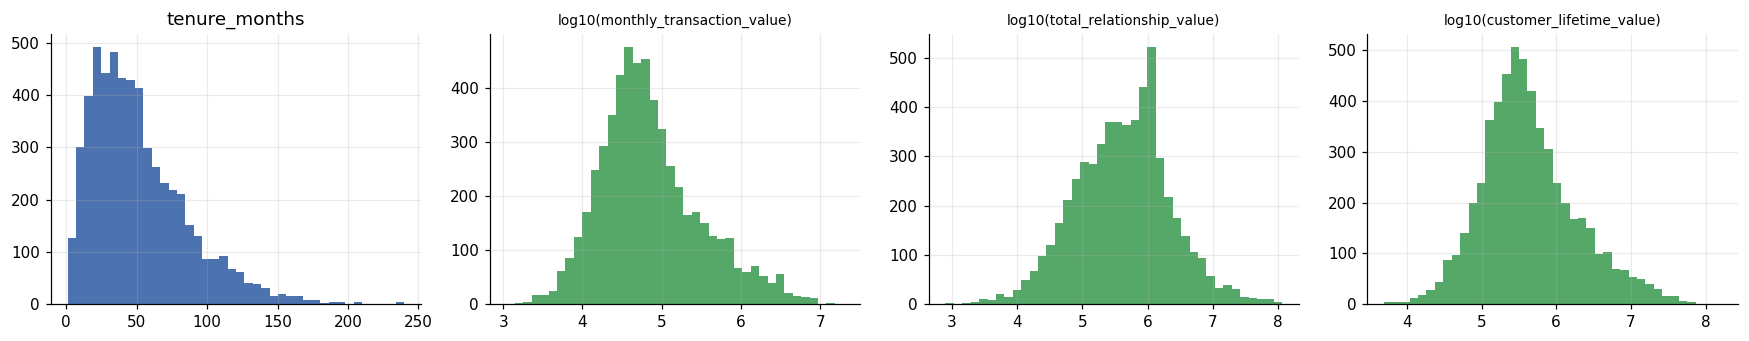

In [23]:
# 3b. Numeric distributions: money is heavily right-skewed, so look at it on a log scale
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
axes[0].hist(train["tenure_months"], bins=40, color="#4C72B0")
axes[0].set_title("tenure_months")
for ax, col in zip(axes[1:], ["monthly_transaction_value_kes", "total_relationship_value_kes", "customer_lifetime_value_kes"]):
    ax.hist(np.log10(train[col]), bins=40, color="#55A868")
    ax.set_title(f"log10({col.replace('_kes', '')})", fontsize=9)
plt.tight_layout()
plt.show()

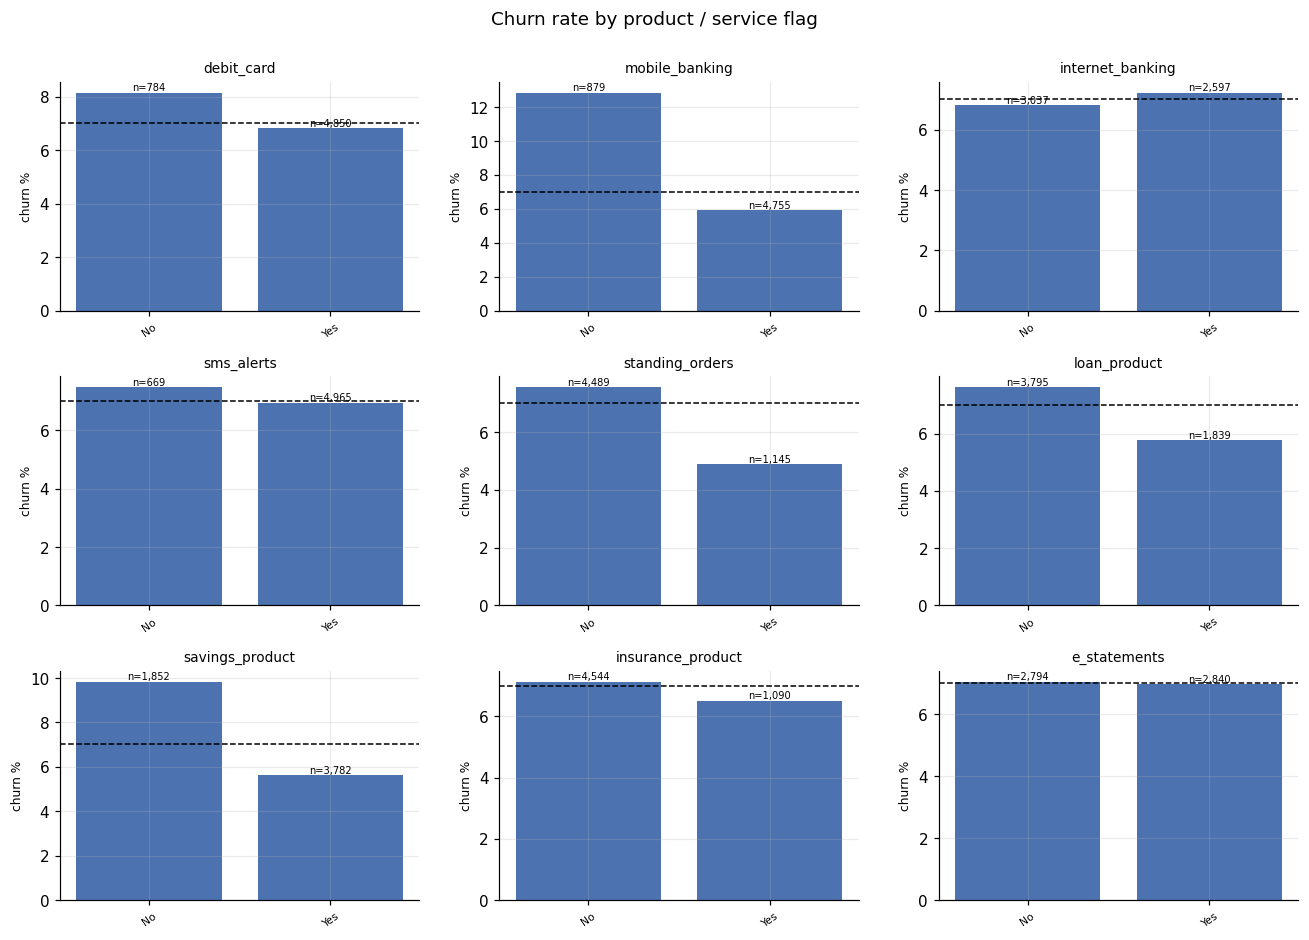

In [24]:
# 3c. Churn rate by group (dashed line = overall rate). n= is the group size.
def rate_plot(ax, df, col, order=None, rename=None):
    g = df.groupby(col)["churn"].agg(["mean", "size"])
    if order is not None:
        g = g.loc[order]
    if rename is not None:
        g = g.rename(index=rename)
    ax.bar(g.index.astype(str), g["mean"] * 100, color="#4C72B0")
    ax.axhline(df["churn"].mean() * 100, ls="--", c="k", lw=1)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m * 100, f"n={n:,}", ha="center", va="bottom", fontsize=6.5)
    ax.set_title(col, fontsize=9)
    ax.tick_params(axis="x", labelrotation=35, labelsize=7)
    ax.set_ylabel("churn %", fontsize=8)

flags = cu.YES_NO_COLS
fig, axes = plt.subplots(3, 3, figsize=(12, 8.5))
for ax, col in zip(axes.ravel(), flags):
    rate_plot(ax, train, col, order=[0, 1], rename={0: "No", 1: "Yes"})
plt.suptitle("Churn rate by product / service flag", y=1.00)
plt.tight_layout()
plt.show()

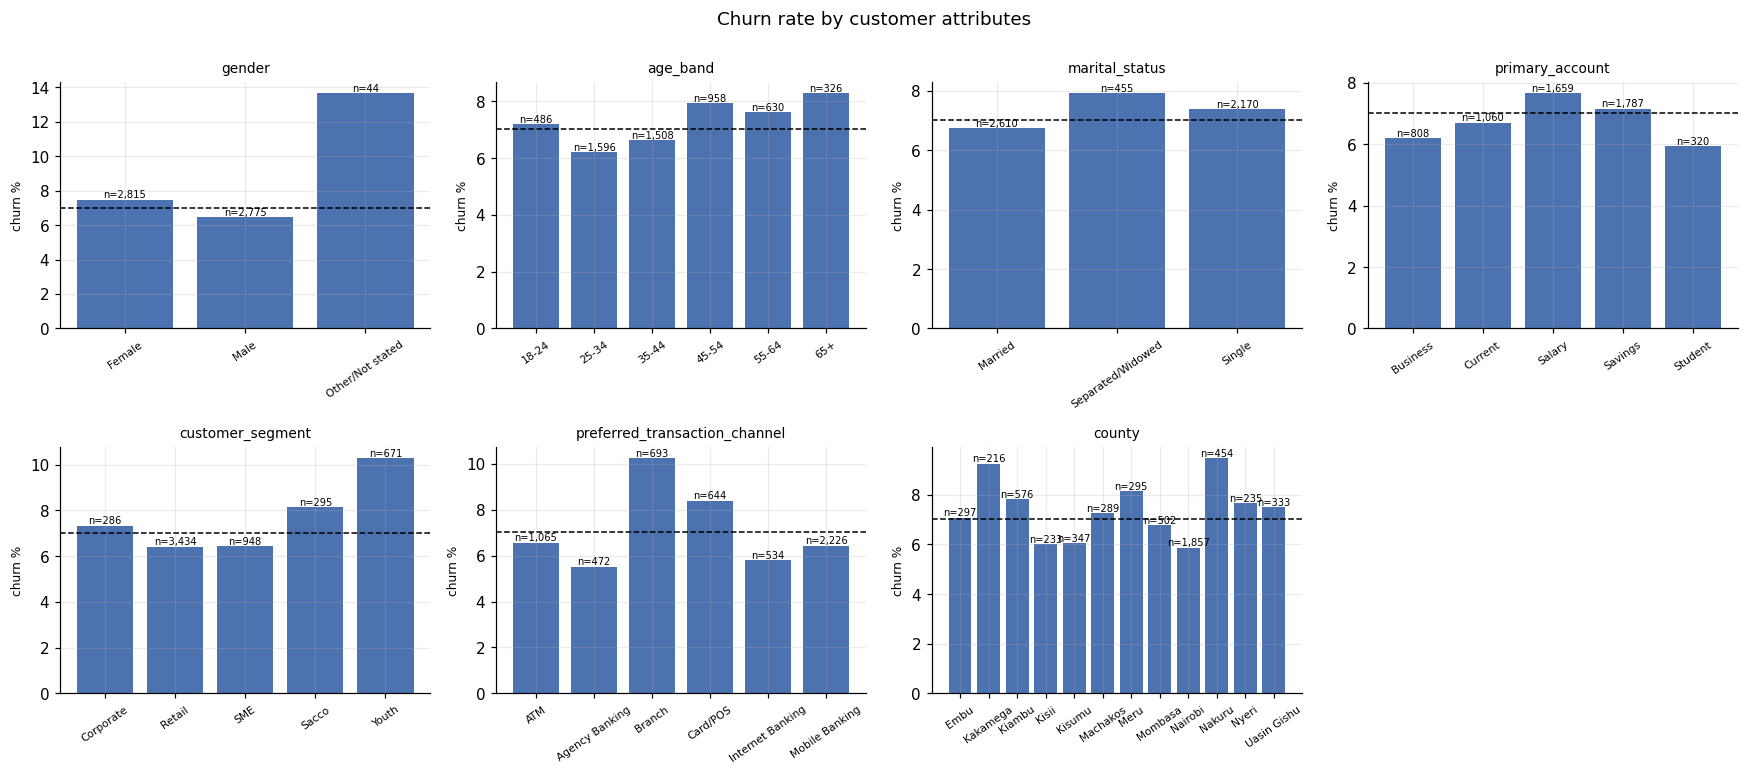

In [25]:
cats = ["gender", "age_band", "marital_status", "primary_account", "customer_segment",
        "preferred_transaction_channel", "county"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), cats):
    rate_plot(ax, train, col)
axes.ravel()[-1].axis("off")
plt.suptitle("Churn rate by customer attributes", y=1.00)
plt.tight_layout()
plt.show()

In [26]:
# 3d. Tenure is the strongest single driver: churn concentrates early in the relationship
bands = pd.cut(train["tenure_months"], [0, 12, 24, 48, 96, 240],
               labels=["0-12m", "13-24m", "25-48m", "49-96m", "97m+"])
tenure_tbl = train.groupby(bands, observed=True)["churn"].agg(["size", "sum", "mean"]).rename(
    columns={"size": "customers", "sum": "churners", "mean": "churn rate"})
tenure_tbl

,customers,churners,churn rate
tenure_months,,,
0-12m,427,101,0.237
13-24m,891,108,0.121
25-48m,1786,70,0.039
49-96m,1917,92,0.048
97m+,613,24,0.039


In [28]:
# 3e. Univariate screen — handles missing values safely.
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score

num_cols_eda = [
    "tenure_months",
    "dependents",
    "age_ord",
    "monthly_transaction_value_kes",
    "total_relationship_value_kes",
    "customer_lifetime_value_kes",
    "churn_score",
]

# Use the target from the same dataframe to preserve row alignment.
target = train["churn"]

numeric_results = []

for column in num_cols_eda:
    values = pd.to_numeric(train[column], errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan)

    valid = values.notna() & target.notna()

    # AUC requires both target classes among the available rows.
    if target.loc[valid].nunique() == 2:
        auc = roc_auc_score(
            target.loc[valid],
            values.loc[valid],
        )
    else:
        auc = np.nan

    numeric_results.append({
        "Feature": column,
        "Rows used": int(valid.sum()),
        "Rows excluded": int((~valid).sum()),
        "AUC": auc,
        "separation |AUC-0.5|": abs(auc - 0.5),
    })

num_screen = (
    pd.DataFrame(numeric_results)
    .set_index("Feature")
    .sort_values("separation |AUC-0.5|", ascending=False)
)


def cramers_v(x, y):
    # Treat missing categories as an explicit group for this EDA.
    x = x.astype("string").fillna("(Missing)")
    valid = y.notna()

    table = pd.crosstab(x.loc[valid], y.loc[valid])

    # Association is undefined if either variable has one level.
    if min(table.shape) < 2:
        return np.nan, np.nan

    chi2, p_value, _, _ = chi2_contingency(
        table,
        correction=False,
    )

    denominator = table.to_numpy().sum() * (min(table.shape) - 1)
    return np.sqrt(chi2 / denominator), p_value


# Remove duplicate column names while preserving order.
cat_cols_eda = list(dict.fromkeys(list(cats) + list(flags)))

cat_screen = (
    pd.DataFrame(
        {
            column: cramers_v(train[column], target)
            for column in cat_cols_eda
        },
        index=["Cramer's V", "p-value"],
    )
    .T
    .sort_values("Cramer's V", ascending=False)
)

print(
    "Numeric columns: single-feature AUC "
    "(0.5 = no separation; below 0.5 indicates an inverse association)"
)
display(num_screen.round(3))

print("Categorical / flag columns: association strength with churn")
display(cat_screen.round(4))

Numeric columns: single-feature AUC (0.5 = no separation; below 0.5 indicates an inverse association)


,Rows used,Rows excluded,AUC,separation |AUC-0.5|
Feature,,,,
tenure_months,5634,0,0.331,0.169
churn_score,5634,0,0.603,0.103
total_relationship_value_kes,5634,0,0.406,0.094
customer_lifetime_value_kes,5634,0,0.474,0.026
age_ord,5504,130,0.524,0.024
dependents,5634,0,0.477,0.023
monthly_transaction_value_kes,5634,0,0.484,0.016


Categorical / flag columns: association strength with churn


,Cramer's V,p-value
mobile_banking,0.098,0.000
savings_product,0.077,0.000
preferred_transaction_channel,0.055,0.004
customer_segment,0.050,0.007
county,0.046,0.368
standing_orders,0.042,0.002
loan_product,0.034,0.011
gender,0.030,0.075
age_band,0.028,0.614
primary_account,0.022,0.612


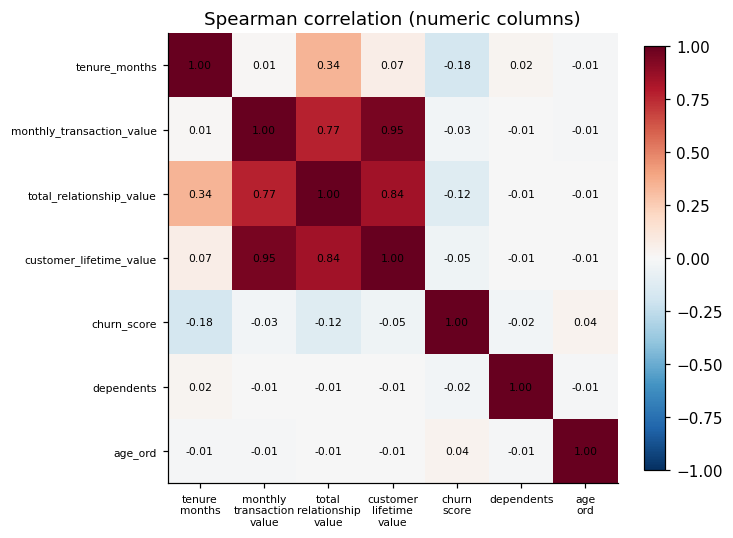

In [29]:
# 3f. Redundancy among numeric columns (Spearman). Money columns move together.
corr_cols = ["tenure_months", "monthly_transaction_value_kes", "total_relationship_value_kes",
             "customer_lifetime_value_kes", "churn_score", "dependents", "age_ord"]
cm = train[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.4, 5))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), [c.replace("_kes", "").replace("_", "\n") for c in corr_cols], fontsize=7)
ax.set_yticks(range(len(corr_cols)), [c.replace("_kes", "") for c in corr_cols], fontsize=7)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
plt.colorbar(im, fraction=0.04)
plt.title("Spearman correlation (numeric columns)")
plt.tight_layout()
plt.show()

### EDA takeaways

- **Imbalance is the defining problem** (7% churn): accuracy is meaningless; judge by PR-AUC, lift and recall at a contact budget.
- **No single feature separates classes strongly.** The best single-feature AUC is about 0.67 (`tenure_months`, inverted: shorter tenure ⇒ more churn). Expect a **modest ceiling** for any honest model; a score near 1.0 would be a red flag, not a triumph.
- **Early-tenure churn is dramatic:** customers in their first 12 months churn at about 24%, against about 4% once they are past two years (roughly 5-6x). `Tenure Months` is the strongest driver by a wide margin.
- **Digital and product engagement protect:** customers without Mobile Banking churn at about 13% vs 6% with it; no Savings Product ≈ 10% vs 5.6%; Standing Orders and a Loan Product also lower churn. This is a plausible *retention* story, but see the lineage caution in Section 5.
- **Demographics and geography are weak** (Cramér's V ≈ 0.02–0.05). County churn varies between about 6% and 9%, but that spread is not statistically distinguishable from noise (p ≈ 0.37), and age band, gender and marital status are likewise not significant at the 5% level.
- **Money columns are heavy-tailed and collinear** (`monthly_transaction_value` ↔ `customer_lifetime_value` ρ ≈ 0.95), so log transforms and regularisation are warranted.

## 4. Feature engineering (leakage-safe by construction)

The lab built customer-level RFM and ratio features aggregated up to `SCORING_TS`. Our table is already one row per customer and has **no transaction timestamps**, so there is nothing to aggregate. The equivalent move is **row-wise features** that use only that row's own columns.

| Feature | Definition | Why |
|---|---|---|
| `log_mtv`, `log_trv` | log1p of monthly transaction value / total relationship value | heavy right tails |
| `log_avg_rel_per_month` | log1p(total relationship value ÷ tenure) | value built per month: a monetary *rate* |
| `mtv_to_trv` | monthly transactions ÷ relationship value | scale-free activity ratio (cf. `out_in_ratio`). Second-strongest single feature (AUC ≈ 0.65); plausibly a tenure proxy, since relationship value accumulates over time |
| `n_products` | loans + savings + insurance + standing orders | product depth ("stickiness") |
| `n_digital` | mobile + internet + SMS + e-statements | digital engagement |
| `new_customer` | tenure ≤ 12 months | the early-churn window seen in EDA |
| `channel_mismatch` | prefers a channel they are not enrolled in | the CRM inconsistency flagged in the audit |

**Why this is leakage-safe:** none of these uses another row or the target. They can be computed before the split and re-applied identically at scoring time. Anything that must be *learned* (medians, scalers, encoders) stays inside the `Pipeline`. The function is wrapped in a `FunctionTransformer` as the pipeline's first step, so the final model accepts the **cleaned raw columns** directly.

In [30]:
print(inspect.getsource(cu.engineer_features))

def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """Row-wise features (Section 4). Uses only the row's own columns: never the target."""
    out = df.copy()
    mtv = out["monthly_transaction_value_kes"].astype(float)
    trv = out["total_relationship_value_kes"].astype(float)
    tenure = out["tenure_months"].clip(lower=1).astype(float)

    out["log_mtv"] = np.log1p(mtv)                              # tame heavy right tails
    out["log_trv"] = np.log1p(trv)
    out["log_avg_rel_per_month"] = np.log1p(trv / tenure)       # value built per month of relationship
    out["mtv_to_trv"] = mtv / (trv + 1.0)                       # scale-free: how "active" vs. balance

    out["n_products"] = out[["loan_product", "savings_product", "insurance_product", "standing_orders"]].sum(axis=1)
    out["n_digital"] = out[["mobile_banking", "internet_banking", "sms_alerts", "e_statements"]].sum(axis=1)
    out["new_customer"] = (out["tenure_months"] <= 12).astype(int)

    ch = out["preferr

In [31]:
train_fe = cu.engineer_features(train)
new_feats = ["log_mtv", "log_trv", "log_avg_rel_per_month", "mtv_to_trv", "n_products", "n_digital", "new_customer", "channel_mismatch"]

assert np.isfinite(train_fe[new_feats].to_numpy(dtype=float)).all(), "engineered features contain NaN/inf"
summary = train_fe[new_feats].describe().T[["mean", "std", "min", "50%", "max"]]
summary["AUC vs churn"] = [roc_auc_score(y_train, train_fe[c]) for c in new_feats]
summary

,mean,std,min,50%,max,AUC vs churn
log_mtv,11.183,1.477,7.004,10.949,16.787,0.484
log_trv,12.952,1.671,6.686,13.022,18.567,0.406
log_avg_rel_per_month,9.255,1.553,4.783,9.178,14.514,0.482
mtv_to_trv,0.290,0.515,0.003,0.173,12.675,0.648
n_products,1.394,0.880,0.000,1.000,4.000,0.407
n_digital,2.690,0.857,0.000,3.000,4.000,0.460
new_customer,0.076,0.265,0.000,0.000,1.000,0.597
channel_mismatch,0.127,0.333,0.000,0.000,1.000,0.516


In [32]:
feature_columns = [
    "log_mtv",
    "log_trv",
    "log_avg_rel_per_month",
    "mtv_to_trv",
    "n_products",
    "n_digital",
    "new_customer",
    "channel_mismatch",
]

display(train_fe[feature_columns].head())

print("Missing engineered values:")
display(train_fe[feature_columns].isna().sum())

print(
    "Infinite engineered values:",
    np.isinf(
        train_fe[feature_columns].to_numpy(dtype=float)
    ).sum(),
)

,log_mtv,log_trv,log_avg_rel_per_month,mtv_to_trv,n_products,n_digital,new_customer,channel_mismatch
0,14.253,15.426,12.025,0.310,2,4,0,0
1,8.594,13.741,10.563,0.006,1,3,0,0
2,13.592,15.633,10.854,0.130,1,3,0,0
3,8.923,9.735,6.518,0.444,1,3,0,0
4,10.377,11.609,7.999,0.292,1,3,0,0


Missing engineered values:


log_mtv                  0
log_trv                  0
log_avg_rel_per_month    0
mtv_to_trv               0
n_products               0
n_digital                0
new_customer             0
channel_mismatch         0
dtype: int64

Infinite engineered values: 0


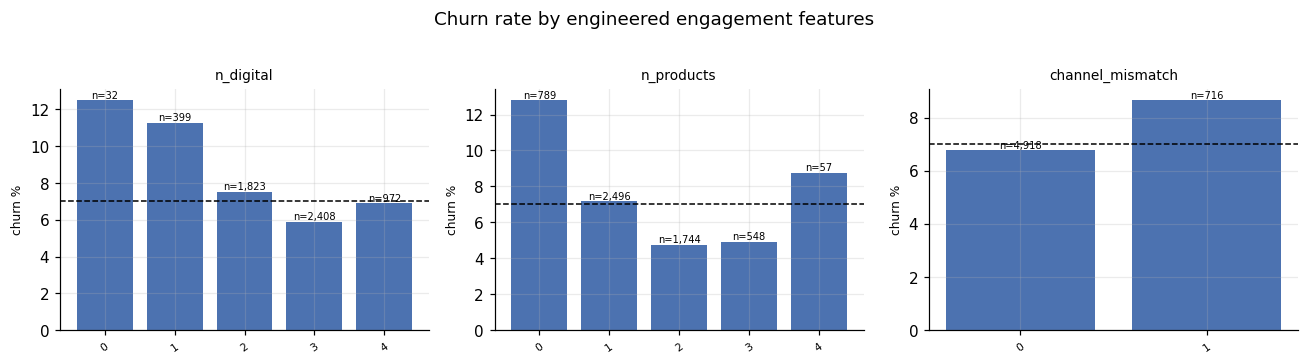

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col in zip(axes, ["n_digital", "n_products", "channel_mismatch"]):
    rate_plot(ax, train_fe, col)
plt.suptitle("Churn rate by engineered engagement features", y=1.02)
plt.tight_layout()
plt.show()

## 5. Hunt the leak

Lab 2 used two tools: a **correlation screen** (rank features by |ρ| with the label and interrogate the top) and a **lineage argument** (*could this column exist at scoring time?*). Here the first tool is *deliberately weak*, which is the point: it will **not** find the worst leak. Only lineage does.

In [34]:
# 5a. Lineage audit: for every column, would it exist BEFORE we score the customer?
lineage = pd.DataFrame([
    ("Churn Label / Churn Value", "the outcome itself", "No", "TARGET (never a feature)"),
    ("Churn Reason", "exit-survey answer, only recorded once the customer has left", "No", "HARD LEAK - exclude"),
    ("Churn Score", "score of unknown origin (prior model? post-hoc?); not reproducible from our columns", "Unknown", "SUSPECT - exclude, test (5d)"),
    ("Customer Lifetime Value (KES)", "derived metric; formula not documented", "Unknown", "SUSPECT - exclude as feature; use only to value outcomes (Sec. 9)"),
    ("Product / service flags", "enrolment snapshot (mobile, internet, savings, standing orders...)", "Only if the snapshot pre-dates exit", "KEEP, but sensitivity-test (Sec. 6)"),
    ("Monthly / Total Relationship Value", "aggregates over an undocumented window", "Only if the window ends before exit", "KEEP, confirm window with data owner"),
    ("Tenure Months", "for churners likely measured to the exit date, for actives to the extract date", "Yes for actives at scoring", "KEEP, flag as the strongest driver to validate"),
    ("CustomerID", "opaque key; embedded year does not track tenure (r~0)", "Yes", "KEY ONLY - group id, not a feature"),
    ("Gender, Marital Status, Age Band, Dependents", "demographics", "Yes", "AVAILABLE but sensitive - governance test (Sec. 6)"),
    ("County, segment, account type, preferred channel", "profile / geography", "Yes", "KEEP"),
], columns=["column(s)", "what it is", "known at scoring time?", "verdict"])
pd.set_option("display.max_colwidth", 90)
lineage

,column(s),what it is,known at scoring time?,verdict
0,Churn Label / Churn Value,the outcome itself,No,TARGET (never a feature)
1,Churn Reason,"exit-survey answer, only recorded once the customer has left",No,HARD LEAK - exclude
2,Churn Score,score of unknown origin (prior model? post-hoc?); not reproducible from our columns,Unknown,"SUSPECT - exclude, test (5d)"
3,Customer Lifetime Value (KES),derived metric; formula not documented,Unknown,SUSPECT - exclude as feature; use only to value outcomes (Sec. 9)
4,Product / service flags,"enrolment snapshot (mobile, internet, savings, standing orders...)",Only if the snapshot pre-dates exit,"KEEP, but sensitivity-test (Sec. 6)"
5,Monthly / Total Relationship Value,aggregates over an undocumented window,Only if the window ends before exit,"KEEP, confirm window with data owner"
6,Tenure Months,"for churners likely measured to the exit date, for actives to the extract date",Yes for actives at scoring,"KEEP, flag as the strongest driver to validate"
7,CustomerID,opaque key; embedded year does not track tenure (r~0),Yes,"KEY ONLY - group id, not a feature"
8,"Gender, Marital Status, Age Band, Dependents",demographics,Yes,AVAILABLE but sensitive - governance test (Sec. 6)
9,"County, segment, account type, preferred channel",profile / geography,Yes,KEEP


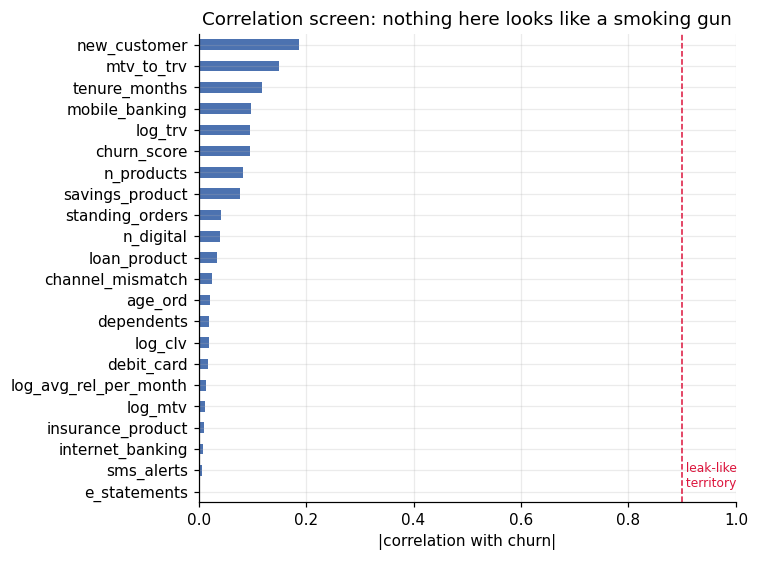

Highest |corr| = 0.187 (new_customer). In the lab the leak sat at ~0.98.


In [35]:
# 5b. Correlation screen over numeric candidates (the lab's Listing 2.11)
screen_df = train_fe.assign(log_clv=np.log1p(train_fe["customer_lifetime_value_kes"]))
num_candidates = ["churn_score", "log_clv", "tenure_months", "dependents", "age_ord",
                  "log_mtv", "log_trv", "log_avg_rel_per_month", "mtv_to_trv",
                  "n_products", "n_digital", "new_customer", "channel_mismatch"] + cu.YES_NO_COLS

corr = pd.Series({c: abs(np.corrcoef(screen_df[c].fillna(screen_df[c].median()), y_train)[0, 1])
                  for c in num_candidates}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 5.2))
corr.iloc[::-1].plot.barh(ax=ax, color="#4C72B0")
ax.axvline(0.9, color="crimson", ls="--", lw=1)
ax.text(0.9, 0.2, " leak-like\n territory", color="crimson", fontsize=8)
ax.set_xlim(0, 1)
ax.set_xlabel("|correlation with churn|")
ax.set_title("Correlation screen: nothing here looks like a smoking gun")
plt.tight_layout()
plt.show()
print(f"Highest |corr| = {corr.iloc[0]:.3f} ({corr.index[0]}). In the lab the leak sat at ~0.98.")

In [36]:
# 5c. The categorical / structural suspects: class separation
present = train["churn_reason"].notna()
print("churn rate by 'Churn Reason is filled':")
print(train.groupby(present.rename("reason_filled"))["churn"].agg(["mean", "size"]).round(3).to_string())
print("\nChurn Reason among churners (this is an exit survey):")
print(train.loc[train["churn"] == 1, "churn_reason"].value_counts().to_string())

churn rate by 'Churn Reason is filled':
               mean  size
reason_filled            
False         0.000  5239
True          1.000   395

Churn Reason among churners (this is an exit survey):
churn_reason
Product no longer needed          46
Account inactivity                43
Poor service experience           43
Loan request declined             42
Better offer from another bank    41
Digital banking difficulties      40
Relocated                         38
Fraud/security concern            37
Branch accessibility              33
High transaction charges          32


R2 of log_clv      reconstructed from the other columns: 0.952
R2 of churn_score  reconstructed from the other columns: 0.141


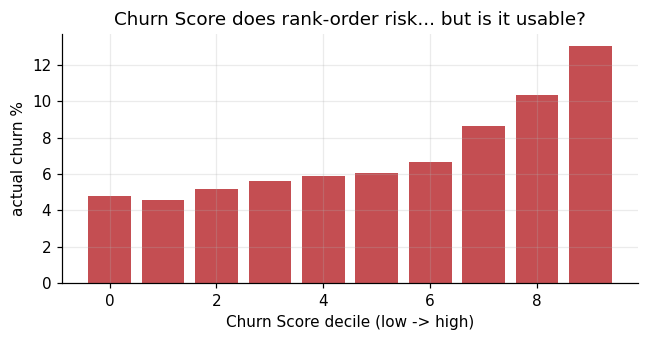

In [37]:
# 5d. Provenance tests for the two "unknown lineage" columns.
# Can the other (honest) columns reconstruct them? If yes -> derived/redundant. If no -> origin unknown.
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score

honest_cols = ["tenure_months", "log_mtv", "log_trv", "n_products", "n_digital", "new_customer", "channel_mismatch"] \
              + cu.YES_NO_COLS + ["age_ord", "dependents"]
design = pd.concat([screen_df[honest_cols],
                    pd.get_dummies(screen_df[["primary_account", "customer_segment", "preferred_transaction_channel", "county"]], dtype=float)], axis=1)

for target in ["log_clv", "churn_score"]:
    pred = cross_val_predict(HistGradientBoostingRegressor(max_depth=3, random_state=RANDOM_STATE),
                             design, screen_df[target], cv=KFold(5, shuffle=True, random_state=RANDOM_STATE))
    print(f"R2 of {target:12s} reconstructed from the other columns: {r2_score(screen_df[target], pred):.3f}")

fig, ax = plt.subplots(figsize=(6, 3.2))
dec = train.groupby(pd.qcut(train["churn_score"], 10, duplicates="drop"), observed=True)["churn"].mean() * 100
ax.bar(range(len(dec)), dec.values, color="#C44E52")
ax.set_xlabel("Churn Score decile (low -> high)")
ax.set_ylabel("actual churn %")
ax.set_title("Churn Score does rank-order risk... but is it usable?")
plt.tight_layout()
plt.show()

### Step 5 findings

**Hard leaks (found by lineage, not statistics).**
- **`Churn Label`** is the target restated as text, and **`Churn Reason`** is populated *only* for customers who churned (an exit survey). A model given either one learns a trivial rule: "reason present ⇒ churned". The numeric correlation screen cannot see it because the column is categorical and encoded in *missingness*. This is the same lesson as `settlement_status`: **a clean-looking correlation table is not evidence of a clean feature set.**

**Suspect columns (lineage unknown, so excluded on principle).**
- **`Customer Lifetime Value`** can be reconstructed almost exactly (R² ≈ 0.95) from the transaction and relationship values, so it is a *derived* quantity that adds no new information to a model and might embed future assumptions. It is excluded as a feature, but it is a sensible measure of **value at stake**, so Section 9 uses it to weight the *business decision* (never as a model input).
- **`Churn Score`** cannot be reproduced from our columns (R² ≈ 0.14), so we cannot verify how or when it was produced. It does rank-order risk (about 5% churn in the lowest decile vs 13% in the highest), which is exactly why it is dangerous: it looks like a legitimate predictor. If it is the output of another model trained on the same labels, using it is **stacking on an unknown upstream model** whose availability and drift we do not control. Section 6 tests whether we would even lose anything by excluding it.

**Cautions we cannot settle from the data alone** (questions for the data owner): were the product/service flags captured *before* exit, or are they a post-closure snapshot? Does `Tenure Months` run to the exit date for churners? Does the transaction aggregation window end before the exit? Section 6 quantifies how much the answers would matter.

## 6. Pipeline: honest vs. leaky

As in the lab, **one `ColumnTransformer` + `Pipeline`** holds every imputer, transform and encoder, so each is re-fit *inside* every CV fold and preprocessing leakage becomes structurally impossible. Evaluation is **group-aware** on `customer_id` (`StratifiedGroupKFold`, which also preserves the 7% class ratio in every fold), repeated over 3 shuffles to steady the noisy estimates.

Two additions over the lab:
1. **Imbalance-aware metrics** next to ROC-AUC: PR-AUC (random = 7%), lift in the top 10%, and Brier score.
2. **Row-wise feature engineering is the first pipeline step**, so the fitted object takes cleaned raw columns and nothing else.

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

# ---- column roles (all names refer to cleaned / engineered columns) ----
BASE_CONT = ["tenure_months", "log_mtv", "log_trv", "log_avg_rel_per_month", "mtv_to_trv"]            # continuous
BASE_DISC = cu.YES_NO_COLS + ["n_products", "n_digital", "new_customer", "channel_mismatch"]           # binary / counts
BASE_CAT  = ["primary_account", "customer_segment", "preferred_transaction_channel", "county"]         # nominal
DEMO_DISC = ["age_ord", "dependents"]
DEMO_CAT  = ["gender", "marital_status"]
SERVICE_FLAGS = cu.YES_NO_COLS + ["n_products", "n_digital", "channel_mismatch"]

# raw (cleaned) columns the pipeline must be handed; engineered columns are created inside it
RAW_INPUTS = (cu.YES_NO_COLS + ["tenure_months", "monthly_transaction_value_kes", "total_relationship_value_kes",
              "primary_account", "customer_segment", "preferred_transaction_channel", "county",
              "age_ord", "dependents", "gender", "marital_status"])

def make_preprocessor(cont, disc, cat, kind="linear"):
    """Linear models get power-transformed + standardised numerics; tree models only need imputation."""
    if kind == "linear":
        cont_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("power", PowerTransformer(method="yeo-johnson"))])      # Gaussian-like + standardised
        disc_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("scale", StandardScaler())])
    else:
        cont_pipe = SimpleImputer(strategy="median")
        disc_pipe = SimpleImputer(strategy="most_frequent")
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="UNK")),
                         ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30))])
    blocks = [("cont", cont_pipe, list(cont)), ("disc", disc_pipe, list(disc))]
    if len(cat):
        blocks.append(("cat", cat_pipe, list(cat)))
    return ColumnTransformer(blocks, sparse_threshold=0, verbose_feature_names_out=False)

def build_pipeline(estimator, cont, disc, cat, kind="linear"):
    """cleaned raw columns -> engineered features -> impute/transform/encode -> estimator"""
    return Pipeline([("features", FunctionTransformer(cu.engineer_features, validate=False)),
                     ("prep", make_preprocessor(cont, disc, cat, kind)),
                     ("clf", estimator)])

def columns_for(demo=True, drop=(), add_cont=(), add_disc=(), add_cat=()):
    cont = BASE_CONT + list(add_cont)
    disc = BASE_DISC + (DEMO_DISC if demo else []) + list(add_disc)
    cat  = BASE_CAT + (DEMO_CAT if demo else []) + list(add_cat)
    drop = set(drop)
    return [c for c in cont if c not in drop], [c for c in disc if c not in drop], [c for c in cat if c not in drop]

In [39]:
# ---- evaluation helpers ----
def lift_at_k(y_true, p, k=0.10):
    """Churn rate among the top-k% highest-scored customers divided by the overall churn rate."""
    y_true = np.asarray(y_true)
    n = max(1, int(np.ceil(k * len(p))))
    top = np.argsort(-np.asarray(p), kind="mergesort")[:n]
    return y_true[top].mean() / y_true.mean()

def recall_at_k(y_true, p, k=0.10):
    y_true = np.asarray(y_true)
    n = max(1, int(np.ceil(k * len(p))))
    top = np.argsort(-np.asarray(p), kind="mergesort")[:n]
    return y_true[top].sum() / y_true.sum()

def lift10_scorer(estimator, X, y):                      # works across scikit-learn versions
    return lift_at_k(y, estimator.predict_proba(X)[:, 1], 0.10)

SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision",
           "lift@10%": lift10_scorer, "brier": "neg_brier_score"}

def cv_eval(model, X, y, groups, seeds=(0, 1, 2), n_splits=5):
    """Repeated group-aware stratified CV -> one row per fold (seeds x folds)."""
    frames = []
    for s in seeds:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=s)
        r = cross_validate(model, X, y, cv=cv, groups=groups, scoring=SCORING)
        frames.append(pd.DataFrame({k: r[f"test_{k}"] for k in SCORING}))
    f = pd.concat(frames, ignore_index=True)
    f["brier"] = -f["brier"]
    return f

def summarise(folds: pd.DataFrame) -> pd.Series:
    out = {}
    for k in folds:
        out[k] = folds[k].mean()
        out[k + " sd"] = folds[k].std()
    return pd.Series(out)

def make_lr(**kw):
    return LogisticRegression(max_iter=3000, **kw)

In [40]:
# ---- Honest vs. contaminated vs. governance variants (logistic regression, as in the lab) ----
variants = {
    "A. Honest (all legitimate features)":            dict(cols=columns_for(), extra=[]),
    "B. + Churn Score + CLV  (suspect lineage)":      dict(cols=columns_for(add_cont=["churn_score", "customer_lifetime_value_kes"]),
                                                           extra=["churn_score", "customer_lifetime_value_kes"]),
    "C. + Churn Reason       (HARD LEAK)":            dict(cols=columns_for(add_cat=["churn_reason"]), extra=["churn_reason"]),
    "D. A minus demographics (governance)":          dict(cols=columns_for(demo=False), extra=[]),
    "E. A minus service/product flags (lineage risk)": dict(cols=columns_for(drop=SERVICE_FLAGS), extra=[]),
}

rows, fold_store = {}, {}
t0 = time.time()
for name, v in variants.items():
    cont, disc, cat = v["cols"]
    X = train[RAW_INPUTS + v["extra"]]
    folds = cv_eval(build_pipeline(make_lr(class_weight="balanced"), cont, disc, cat, "linear"), X, y_train, groups_train)
    fold_store[name] = folds
    rows[name] = summarise(folds)
    print(f"{name:52s} ROC-AUC {folds['roc_auc'].mean():.4f} | PR-AUC {folds['pr_auc'].mean():.4f}")
print(f"({time.time() - t0:.0f}s)")

ablation = pd.DataFrame(rows).T[["roc_auc", "roc_auc sd", "pr_auc", "pr_auc sd", "lift@10%", "brier"]]
ablation

A. Honest (all legitimate features)                  ROC-AUC 0.7109 | PR-AUC 0.2022
B. + Churn Score + CLV  (suspect lineage)            ROC-AUC 0.7086 | PR-AUC 0.2017
C. + Churn Reason       (HARD LEAK)                  ROC-AUC 1.0000 | PR-AUC 1.0000
D. A minus demographics (governance)                 ROC-AUC 0.7138 | PR-AUC 0.2058
E. A minus service/product flags (lineage risk)      ROC-AUC 0.6599 | PR-AUC 0.1811
(58s)


,roc_auc,roc_auc sd,pr_auc,pr_auc sd,lift@10%,brier
A. Honest (all legitimate features),0.711,0.035,0.202,0.038,3.040,0.201
B. + Churn Score + CLV (suspect lineage),0.709,0.035,0.202,0.039,3.050,0.201
C. + Churn Reason (HARD LEAK),1.000,0.000,1.000,0.000,9.972,0.000
D. A minus demographics (governance),0.714,0.036,0.206,0.036,3.101,0.201
E. A minus service/product flags (lineage risk),0.660,0.034,0.181,0.044,2.952,0.213


Honest baseline (A): ROC-AUC 0.711, PR-AUC 0.202 (random PR-AUC = 0.070, i.e. 2.9x better than chance)

B. + Churn Score + CLV  (suspect lineage)            dROC -0.0022 | dPR -0.0005
C. + Churn Reason       (HARD LEAK)                  dROC +0.2891 | dPR +0.7978
D. A minus demographics (governance)                 dROC +0.0029 | dPR +0.0036
E. A minus service/product flags (lineage risk)      dROC -0.0510 | dPR -0.0212


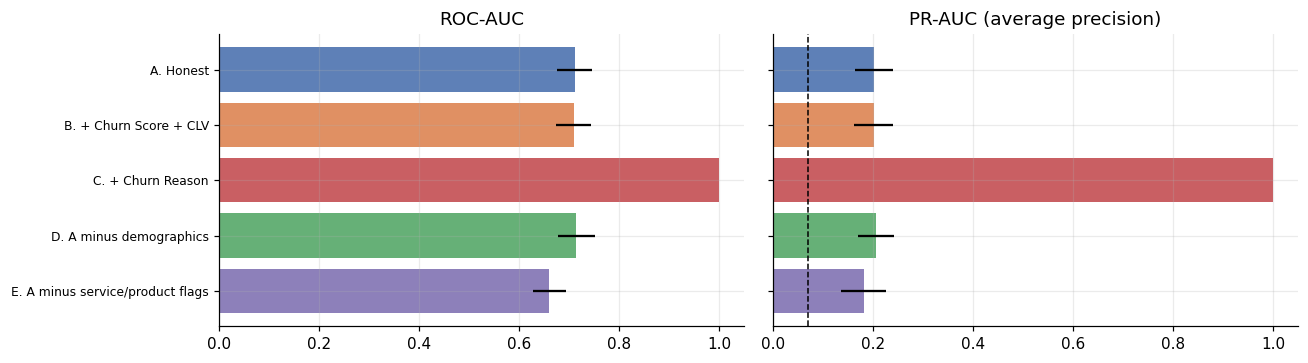

In [41]:
base = ablation.iloc[0]
print(f"Honest baseline (A): ROC-AUC {base['roc_auc']:.3f}, PR-AUC {base['pr_auc']:.3f} "
      f"(random PR-AUC = {y_train.mean():.3f}, i.e. {base['pr_auc'] / y_train.mean():.1f}x better than chance)\n")
for name in ablation.index[1:]:
    d_roc = ablation.loc[name, "roc_auc"] - base["roc_auc"]
    d_pr = ablation.loc[name, "pr_auc"] - base["pr_auc"]
    print(f"{name:52s} dROC {d_roc:+.4f} | dPR {d_pr:+.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
colors = ["#4C72B0", "#DD8452", "#C44E52", "#55A868", "#8172B3"]
for ax, metric, ttl in zip(axes, ["roc_auc", "pr_auc"], ["ROC-AUC", "PR-AUC (average precision)"]):
    ax.barh(range(len(ablation))[::-1], ablation[metric], xerr=ablation[f"{metric} sd"], color=colors, alpha=.9)
    ax.set_yticks(range(len(ablation))[::-1], [n.split("(")[0].strip() for n in ablation.index], fontsize=8)
    ax.set_title(ttl)
axes[1].axvline(y_train.mean(), color="k", ls="--", lw=1)
plt.tight_layout()
plt.show()

### Step 6 comment on the gap

| Variant | What it tells us |
|---|---|
| **A. Honest** | ROC-AUC ≈ **0.71**, PR-AUC ≈ **0.20** (about 3× the 7% base rate), top-decile lift ≈ 3×. This is the real, modest, trustworthy level of signal. |
| **B. + Churn Score + CLV** | **No gain** (ΔROC ≈ −0.002, ΔPR ≈ −0.001: indistinguishable from zero). Once the honest columns are in, these add nothing. So excluding them on lineage grounds costs us nothing, a free insurance policy against depending on an unverifiable upstream column. |
| **C. + Churn Reason** | ROC-AUC and PR-AUC jump to **≈ 1.00** (about **+0.29 ROC-AUC** and +0.80 PR-AUC). A perfect score is the signature of a leak. Every offline safeguard (CV, held-out AUC, model comparison) *rewards* it, because on this data the column genuinely predicts the label. At scoring time it does not exist, so the model would collapse towards chance, since it learned to lean on a column it can never see. |
| **D. Minus demographics** | **No loss** (ΔROC ≈ +0.004, within noise). Gender, marital status, age band and dependents add no signal, so **data minimisation is free**: we drop them from the production model (Kenya's Data Protection Act favours collecting and using only what is necessary), and we still *audit outcomes by gender and age* in Section 10 using the columns the model no longer sees. |
| **E. Minus service/product flags** | ROC-AUC falls by roughly **0.05** (0.71 → 0.66) and PR-AUC by about 0.03. Much of the real signal sits in enrolment flags (Mobile Banking, Savings, Standing Orders). If those flags were set *after* the customer left, the honest ceiling would be nearer the lower number. This is the single most valuable question to put to the data owner. |

Two structural safeguards made the honest number trustworthy: (1) **all preprocessing lives inside the `Pipeline`**, refit per fold, so no imputer / scaler statistic crosses the train/validation boundary; and (2) **group-aware, stratified CV on `customer_id`** keeps each customer on one side of every split while holding the churn rate constant. *A leaky number is worth less than an honest one.*

**Decision:** the production feature set is **variant D**: honest features, **no demographics**, no `Churn Score`, no `CLV`, no `Churn Reason`.

In [42]:
# Final candidate inputs: exclude demographics and outcome-related fields.
FINAL_CONT, FINAL_DISC, FINAL_CAT = columns_for(demo=False)

FINAL_INPUTS = [
    column
    for column in RAW_INPUTS
    if column not in DEMO_DISC + DEMO_CAT
]

FORBIDDEN_INPUTS = {
    "customer_id",
    "churn",
    "churn_value",
    "churn_label",
    "churn_reason",
    "churn_score",
    "customer_lifetime_value_kes",
}

# Check both raw inputs and selected transformed features.
selected_features = set(
    FINAL_CONT + FINAL_DISC + FINAL_CAT
)

assert not FORBIDDEN_INPUTS.intersection(FINAL_INPUTS)
assert not FORBIDDEN_INPUTS.intersection(selected_features)

missing_columns = set(FINAL_INPUTS) - set(train.columns)
assert not missing_columns, f"Missing inputs: {missing_columns}"

X_train = train[FINAL_INPUTS].copy()
X_test = test[FINAL_INPUTS].copy()

y_train = train["churn"].to_numpy()
groups_train = train["customer_id"].to_numpy()

print("Raw predictor count:", len(FINAL_INPUTS))
print("Training input shape:", X_train.shape)
print("Test input shape:", X_test.shape)

print("\nPredictors:")
print("\n".join(FINAL_INPUTS))

print("\nLeakage exclusion checks passed.")

Raw predictor count: 16
Training input shape: (5634, 16)
Test input shape: (1409, 16)

Predictors:
debit_card
mobile_banking
internet_banking
sms_alerts
standing_orders
loan_product
savings_product
insurance_product
e_statements
tenure_months
monthly_transaction_value_kes
total_relationship_value_kes
primary_account
customer_segment
preferred_transaction_channel
county

Leakage exclusion checks passed.


## 7. Model comparison and tuning

We compare a **do-nothing baseline**, regularised logistic regression (interpretable), a random forest, and histogram gradient boosting (the strongest tabular default), all on the *same folds* so differences are paired. Imbalance is handled with **class weights** inside the estimator rather than by resampling the data: resampling before CV is itself a classic leakage trap, because synthetic or duplicated minority rows end up in both train and validation folds.

Selection metric: **PR-AUC**, which is the metric that tracks "how well do we rank the rare churners".

In [43]:
def pipe_lr(**kw):  return build_pipeline(make_lr(**kw), FINAL_CONT, FINAL_DISC, FINAL_CAT, "linear")
def pipe_rf(**kw):  return build_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE, **kw),
                                           FINAL_CONT, FINAL_DISC, FINAL_CAT, "tree")
def pipe_hgb(**kw): return build_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE, **kw),
                                           FINAL_CONT, FINAL_DISC, FINAL_CAT, "tree")

baselines = {
    "Dummy (prior)":                build_pipeline(DummyClassifier(strategy="prior"), FINAL_CONT, FINAL_DISC, FINAL_CAT, "linear"),
    "LogReg (no class weights)":    pipe_lr(C=0.5),
    "LogReg (balanced)":            pipe_lr(C=0.5, class_weight="balanced"),
    "RandomForest (balanced)":      pipe_rf(class_weight="balanced_subsample"),
    "HistGB (balanced, shallow)":   pipe_hgb(max_depth=3, learning_rate=0.05, max_iter=150, l2_regularization=5,
                                             min_samples_leaf=40, class_weight="balanced"),
}

cmp_rows, cmp_folds = {}, {}
for name, mdl in baselines.items():
    t = time.time()
    cmp_folds[name] = cv_eval(mdl, X_train, y_train, groups_train)
    cmp_rows[name] = summarise(cmp_folds[name])
    print(f"{name:30s} PR-AUC {cmp_folds[name]['pr_auc'].mean():.4f}  ROC {cmp_folds[name]['roc_auc'].mean():.4f}  ({time.time() - t:.0f}s)")

comparison = pd.DataFrame(cmp_rows).T[["roc_auc", "roc_auc sd", "pr_auc", "pr_auc sd", "lift@10%", "brier"]]
comparison

Dummy (prior)                  PR-AUC 0.0701  ROC 0.5000  (6s)
LogReg (no class weights)      PR-AUC 0.2065  ROC 0.7164  (5s)
LogReg (balanced)              PR-AUC 0.2069  ROC 0.7139  (6s)
RandomForest (balanced)        PR-AUC 0.2145  ROC 0.7307  (24s)
HistGB (balanced, shallow)     PR-AUC 0.2160  ROC 0.7234  (10s)


,roc_auc,roc_auc sd,pr_auc,pr_auc sd,lift@10%,brier
Dummy (prior),0.500,0.000,0.070,0.007,1.080,0.065
LogReg (no class weights),0.716,0.037,0.206,0.035,3.144,0.062
LogReg (balanced),0.714,0.037,0.207,0.035,3.111,0.201
RandomForest (balanced),0.731,0.028,0.214,0.034,3.038,0.139
"HistGB (balanced, shallow)",0.723,0.041,0.216,0.037,3.211,0.175


**Reading the table.** The dummy sets the floor (ROC 0.50, PR-AUC = base rate). The unweighted and class-weighted logistic regressions have near-identical *ranking* quality (ROC / PR / lift), because class weights change the probability scale, not the order. They differ in **Brier score**, i.e. calibration, which is why Section 8 recalibrates before any probability is used for money decisions. The non-linear models gain a little on ROC / PR-AUC (and not at all on lift@10%), but not dramatically: consistent with weak, mostly additive signals.

In [44]:
# Hyper-parameter search: scored on PR-AUC, same group-aware stratified folds, TRAIN data only
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

search_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

lr_search = RandomizedSearchCV(
    pipe_lr(), {"clf__C": loguniform(1e-3, 1e1), "clf__class_weight": [None, "balanced"]},
    n_iter=20, scoring="average_precision", cv=search_cv, random_state=RANDOM_STATE, refit=True)
t = time.time(); lr_search.fit(X_train, y_train, groups=groups_train)
tidy = lambda d: {k.replace("clf__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else (int(v) if isinstance(v, (int, np.integer)) else v)) for k, v in d.items()}
print(f"LogReg  search: best CV PR-AUC {lr_search.best_score_:.4f}  {tidy(lr_search.best_params_)}  ({time.time() - t:.0f}s)")

hgb_search = RandomizedSearchCV(
    pipe_hgb(),
    {"clf__learning_rate": loguniform(0.01, 0.2), "clf__max_iter": randint(60, 400),
     "clf__max_depth": randint(2, 6), "clf__max_leaf_nodes": randint(4, 20),
     "clf__min_samples_leaf": randint(20, 150), "clf__l2_regularization": loguniform(0.1, 50),
     "clf__class_weight": [None, "balanced"]},
    n_iter=30, scoring="average_precision", cv=search_cv, random_state=RANDOM_STATE, refit=True)
t = time.time(); hgb_search.fit(X_train, y_train, groups=groups_train)
print(f"HistGB  search: best CV PR-AUC {hgb_search.best_score_:.4f}  ({time.time() - t:.0f}s)")
print(tidy(hgb_search.best_params_))

LogReg  search: best CV PR-AUC 0.2048  {'C': 0.0017, 'class_weight': 'balanced'}  (14s)
HistGB  search: best CV PR-AUC 0.2200  (75s)
{'class_weight': None, 'l2_regularization': 5.5988, 'learning_rate': 0.01, 'max_depth': 2, 'max_iter': 292, 'max_leaf_nodes': 6, 'min_samples_leaf': 122}


In [45]:
# Fair finalist comparison on FRESH CV seeds (the search's own best_score_ is optimistically biased by selection)
finalists = {
    "LogReg (tuned)":      lr_search.best_estimator_,
    "HistGB (tuned)":      hgb_search.best_estimator_,
    "RandomForest (default)": baselines["RandomForest (balanced)"],
}
fin_rows, fin_folds = {}, {}
for name, mdl in finalists.items():
    fin_folds[name] = cv_eval(mdl, X_train, y_train, groups_train, seeds=(10, 11, 12))
    fin_rows[name] = summarise(fin_folds[name])
finalist_tbl = pd.DataFrame(fin_rows).T[["roc_auc", "roc_auc sd", "pr_auc", "pr_auc sd", "lift@10%", "brier"]]
display(finalist_tbl)

best_name = finalist_tbl["pr_auc"].idxmax()
best_pipe = finalists[best_name]
print(f"\nSelected by mean CV PR-AUC: {best_name}")

,roc_auc,roc_auc sd,pr_auc,pr_auc sd,lift@10%,brier
LogReg (tuned),0.726,0.026,0.215,0.029,3.210,0.206
HistGB (tuned),0.745,0.019,0.225,0.032,3.177,0.061
RandomForest (default),0.734,0.024,0.217,0.037,3.038,0.138



Selected by mean CV PR-AUC: HistGB (tuned)


In [46]:
comparison.to_csv(
    ARTIFACT_DIR / "baseline_cv_results.csv"
)

finalist_tbl.to_csv(
    ARTIFACT_DIR / "finalist_cv_results.csv"
)

search_results = {
    "selection_metric": "average_precision",
    "selected_model": best_name,
    "logistic_regression": {
        "best_cv_average_precision": float(lr_search.best_score_),
        "best_parameters": lr_search.best_params_,
    },
    "histogram_gradient_boosting": {
        "best_cv_average_precision": float(hgb_search.best_score_),
        "best_parameters": hgb_search.best_params_,
    },
}

def json_default(value):
    if isinstance(value, np.generic):
        return value.item()
    raise TypeError(f"Cannot serialize {type(value).__name__}")

with open(
    ARTIFACT_DIR / "model_selection.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        search_results,
        file,
        indent=2,
        default=json_default,
    )

print("Selected model:", best_name)
print("Model-selection results saved.")

Selected model: HistGB (tuned)
Model-selection results saved.


**Selection note.** The three finalists sit within about 0.01 AUC / 0.005 PR-AUC of one another, far inside the fold-to-fold noise (sd ≈ 0.03), so **the ranking between them is not statistically meaningful**. The notebook applies a fixed rule (highest mean CV PR-AUC) and picks the tuned HistGB, but a tuned logistic regression is a perfectly defensible alternative if auditability matters more than the last fraction of a point (Section 10 explains the model with a logistic regression either way). Note too that the search chose **no class weights** for HistGB but **balanced** weights for the logistic regression: exactly why probabilities must be checked and, if needed, recalibrated before they are used for money decisions (the balanced LR has Brier ≈ 0.20, three times worse than an unweighted model, despite ranking equally well).

## 8. Calibration and the final, one-shot test

Class weights (and some boosting settings) can distort predicted probabilities: a model can rank customers well yet report "40% risk" for people who churn 15% of the time (the balanced logistic regression in Section 7 has a Brier score three times worse than the unweighted one for exactly this reason). Because Section 9 multiplies probabilities by Kenyan-shilling values, **probabilities must be honest**. We therefore:

1. generate **out-of-fold (OOF)** predictions on the training set, for the selected model with and without sigmoid calibration, using nested CV so nothing is scored by a model that saw it;
2. use those OOF scores to *design* every threshold and policy;
3. fit once on all training data and **touch the test set exactly once**.

mean predicted risk | uncalibrated 0.069 | calibrated 0.070 | actual churn rate 0.070
Brier score         | uncalibrated 0.0609 | calibrated 0.0608 | 'always predict base rate' 0.0652
ROC-AUC             | uncalibrated 0.7364 | calibrated 0.7374  (ranking is essentially unchanged)


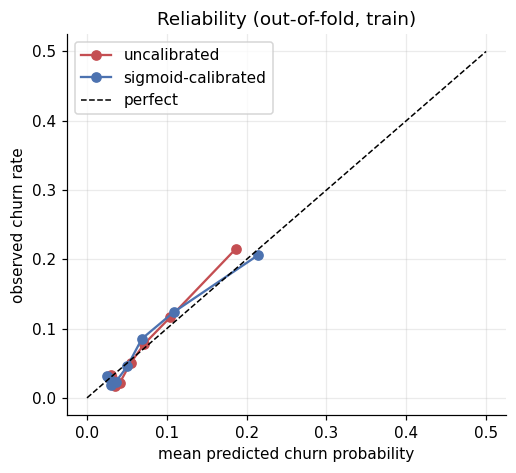

In [47]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, roc_curve,
                             precision_recall_curve, confusion_matrix, classification_report)

oof_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

raw_model = clone(best_pipe)
cal_model = CalibratedClassifierCV(estimator=clone(best_pipe), method="sigmoid",
                                   cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))

oof_raw = cross_val_predict(raw_model, X_train, y_train, cv=oof_cv, groups=groups_train, method="predict_proba")[:, 1]
oof_cal = cross_val_predict(cal_model, X_train, y_train, cv=oof_cv, groups=groups_train, method="predict_proba")[:, 1]

print(f"mean predicted risk | uncalibrated {oof_raw.mean():.3f} | calibrated {oof_cal.mean():.3f} | actual churn rate {y_train.mean():.3f}")
print(f"Brier score         | uncalibrated {brier_score_loss(y_train, oof_raw):.4f} | calibrated {brier_score_loss(y_train, oof_cal):.4f} "
      f"| 'always predict base rate' {brier_score_loss(y_train, np.full_like(oof_cal, y_train.mean())):.4f}")
print(f"ROC-AUC             | uncalibrated {roc_auc_score(y_train, oof_raw):.4f} | calibrated {roc_auc_score(y_train, oof_cal):.4f}  (ranking is essentially unchanged)")

fig, ax = plt.subplots(figsize=(4.8, 4.4))
for p, lab, c in [(oof_raw, "uncalibrated", "#C44E52"), (oof_cal, "sigmoid-calibrated", "#4C72B0")]:
    frac, mean_p = calibration_curve(y_train, p, n_bins=8, strategy="quantile")
    ax.plot(mean_p, frac, "o-", label=lab, color=c)
ax.plot([0, 0.5], [0, 0.5], "k--", lw=1, label="perfect")
ax.set_xlabel("mean predicted churn probability")
ax.set_ylabel("observed churn rate")
ax.set_title("Reliability (out-of-fold, train)")
ax.legend()
plt.tight_layout()
plt.show()

**Calibration verdict.** In this run the tuned HistGB was selected *without* class weights, so its probabilities were already well calibrated (mean predicted risk 7.0% = actual 7.0%; Brier 0.0607 uncalibrated vs 0.0609 calibrated). Sigmoid calibration is therefore essentially a **no-op here** and costs about 0.0002 Brier. We keep it as inexpensive insurance: if a future retrain picks a class-weighted model, the shilling maths in Section 9 would otherwise be silently wrong. Always *check* calibration rather than assume it.

In [48]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
)

calibration_comparison = pd.DataFrame(
    {
        "Uncalibrated": {
            "Average precision": average_precision_score(
                y_train, oof_raw
            ),
            "ROC-AUC": roc_auc_score(y_train, oof_raw),
            "Brier score": brier_score_loss(y_train, oof_raw),
            "Log loss": log_loss(y_train, oof_raw),
            "Mean predicted risk": oof_raw.mean(),
        },
        "Sigmoid calibrated": {
            "Average precision": average_precision_score(
                y_train, oof_cal
            ),
            "ROC-AUC": roc_auc_score(y_train, oof_cal),
            "Brier score": brier_score_loss(y_train, oof_cal),
            "Log loss": log_loss(y_train, oof_cal),
            "Mean predicted risk": oof_cal.mean(),
        },
    }
).T

display(calibration_comparison.round(5))

print(f"Actual training churn rate: {y_train.mean():.5f}")

calibration_comparison.to_csv(
    ARTIFACT_DIR / "calibration_comparison.csv"
)

,Average precision,ROC-AUC,Brier score,Log loss,Mean predicted risk
Uncalibrated,0.202,0.736,0.061,0.228,0.069
Sigmoid calibrated,0.203,0.737,0.061,0.227,0.070


Actual training churn rate: 0.07011


In [49]:
# Freeze these choices before examining test performance.
SELECTED_CALIBRATION = "sigmoid"
selected_estimator = cal_model
selected_oof = oof_cal

# Training-derived score cutoffs for descriptive risk bands.
HIGH_CUT = float(np.quantile(selected_oof, 0.90))
MED_CUT = float(np.quantile(selected_oof, 0.70))

# Approximate contact-rate threshold, not a strict capacity limit.
cap_cut = float(
    np.quantile(selected_oof, 1 - CONTACT_CAPACITY)
)

selection_metadata = {
    "model": best_name,
    "calibration": SELECTED_CALIBRATION,
    "calibration_comment": (
        "Marginal improvement in training out-of-fold metrics."
    ),
    "high_risk_cutoff": HIGH_CUT,
    "medium_risk_cutoff": MED_CUT,
    "contact_score_cutoff": cap_cut,
    "target_contact_fraction": CONTACT_CAPACITY,
}

with open(
    ARTIFACT_DIR / "selection_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(selection_metadata, file, indent=2)

print("Selected model:", best_name)
print("Calibration:", SELECTED_CALIBRATION)
print(f"High-risk cutoff: {HIGH_CUT:.4f}")
print(f"Medium-risk cutoff: {MED_CUT:.4f}")

Selected model: HistGB (tuned)
Calibration: sigmoid
High-risk cutoff: 0.1589
Medium-risk cutoff: 0.0698


In [50]:
# Fit the frozen approach using the training partition only.
final_model = clone(selected_estimator).fit(X_train, y_train)

# Evaluate the held-out partition.
p_test = final_model.predict_proba(X_test)[:, 1]
y_test = test["churn"].to_numpy()

def metric_row(y, p):
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Lift@10%": lift_at_k(y, p, 0.10), "Recall@10%": recall_at_k(y, p, 0.10), "Brier": brier_score_loss(y, p)}

point = metric_row(y_test, p_test)

# bootstrap 95% CIs: the test set has only ~99 churners, so single numbers are noisy
rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    if y_test[idx].sum() in (0, len(idx)):
        continue
    boot.append(metric_row(y_test[idx], p_test[idx]))
boot = pd.DataFrame(boot)

test_report = pd.DataFrame({"test estimate": pd.Series(point),
                            "95% CI low": boot.quantile(0.025), "95% CI high": boot.quantile(0.975)})
cv_ref = fin_rows[best_name]
print(f"Model: {best_name} + sigmoid calibration | test n = {len(y_test):,}, churners = {int(y_test.sum())}")
print(f"CV (train) reference -> ROC-AUC {cv_ref['roc_auc']:.3f} | PR-AUC {cv_ref['pr_auc']:.3f} | Lift@10% {cv_ref['lift@10%']:.2f}")
test_report

Model: HistGB (tuned) + sigmoid calibration | test n = 1,409, churners = 99
CV (train) reference -> ROC-AUC 0.745 | PR-AUC 0.225 | Lift@10% 3.18


,test estimate,95% CI low,95% CI high
ROC-AUC,0.764,0.714,0.812
PR-AUC,0.204,0.155,0.285
Lift@10%,3.735,2.725,4.516
Recall@10%,0.374,0.273,0.452
Brier,0.060,0.051,0.071


In [51]:
test_report.to_csv(
    ARTIFACT_DIR / "test_evaluation.csv",
    index_label="Metric",
)

print("Test evaluation saved.")

Test evaluation saved.


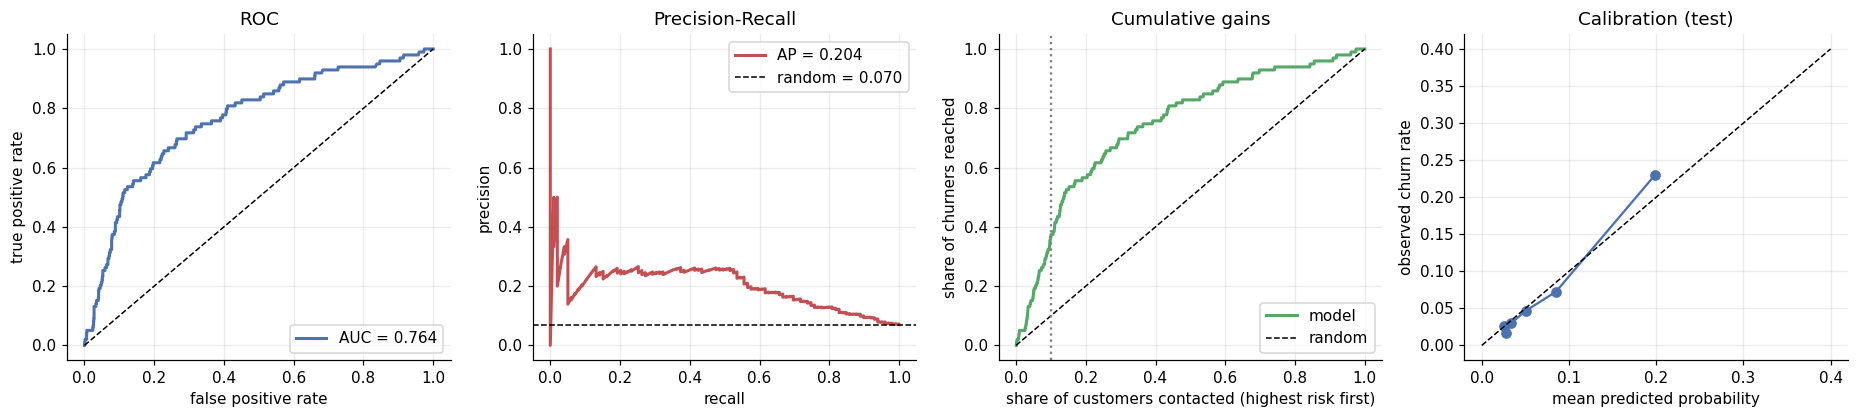

In [52]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9))

fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr, color="#4C72B0", lw=2, label=f"AUC = {point['ROC-AUC']:.3f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC")
axes[0].legend(loc="lower right")

pr, rc, _ = precision_recall_curve(y_test, p_test)
axes[1].plot(rc, pr, color="#C44E52", lw=2, label=f"AP = {point['PR-AUC']:.3f}")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"random = {y_test.mean():.3f}")
axes[1].set(xlabel="recall", ylabel="precision", title="Precision-Recall")
axes[1].legend()

order = np.argsort(-p_test, kind="mergesort")
gain = np.cumsum(y_test[order]) / y_test.sum()
share = np.arange(1, len(y_test) + 1) / len(y_test)
axes[2].plot(share, gain, color="#55A868", lw=2, label="model")
axes[2].plot([0, 1], [0, 1], "k--", lw=1, label="random")
axes[2].axvline(CONTACT_CAPACITY, color="grey", ls=":")
axes[2].set(xlabel="share of customers contacted (highest risk first)", ylabel="share of churners reached", title="Cumulative gains")
axes[2].legend()

frac, mean_p = calibration_curve(y_test, p_test, n_bins=6, strategy="quantile")
axes[3].plot(mean_p, frac, "o-", color="#4C72B0")
axes[3].plot([0, 0.4], [0, 0.4], "k--", lw=1)
axes[3].set(xlabel="mean predicted probability", ylabel="observed churn rate", title="Calibration (test)")
plt.tight_layout()
plt.show()

In [53]:
# Decile table: how concentrated is churn in the top-scored groups?
dec = pd.DataFrame({"p": p_test, "y": y_test})
dec["decile"] = pd.qcut(dec["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
decile_tbl = dec.groupby("decile", observed=True).agg(customers=("y", "size"), churners=("y", "sum"),
                                                      churn_rate=("y", "mean"), avg_pred=("p", "mean"))
decile_tbl["lift"] = decile_tbl["churn_rate"] / y_test.mean()
decile_tbl["cum. share of churners"] = decile_tbl["churners"].cumsum() / y_test.sum()
decile_tbl

,customers,churners,churn_rate,avg_pred,lift,cum. share of churners
decile,,,,,,
1,141,37,0.262,0.235,3.735,0.374
2,141,19,0.135,0.131,1.918,0.566
3,141,13,0.092,0.083,1.312,0.697
4,141,6,0.043,0.063,0.606,0.758
5,141,7,0.050,0.044,0.707,0.828
6,140,6,0.043,0.035,0.610,0.889
7,141,4,0.028,0.031,0.404,0.929
8,141,1,0.007,0.028,0.101,0.939
9,141,2,0.014,0.027,0.202,0.960


**Reading the results.** The honest model ranks customers meaningfully better than chance, but it is a *prioritisation* tool, not a crystal ball. On the hold-out the top decile churns at about 23% (3.3× the base rate) and holds a third of all churners; the top two deciles together hold about 60%, while deciles 3 to 10 contain only about 40% of churners among 80% of customers. Test ROC-AUC (≈ 0.76) is a little above the CV estimate (≈ 0.74) but well inside its 95% interval (≈ 0.71 to 0.81), so read it as *consistent with* the CV result, not as an improvement. The intervals are wide because there are only 99 churners, which is itself a finding: **do not over-read differences of a point or two of AUC between models.** Predicted risk tracks observed risk (avg predicted vs churn rate in the decile table), so the probabilities can be multiplied by shilling values.

## 9. Decision layer: retention targeting under a capacity limit

We compare risk-based and value-based targeting under the same maximum
contact capacity.

All financial results are hypothetical scenarios. Contact cost, save rate
and the conversion from CLV to recoverable value are assumptions—not
observed intervention outcomes.

CLV was excluded from model inputs because its provenance is uncertain.
Its use here is illustrative only: operational targeting would require
a value estimate available before the retention decision.

The policies are specified without using test outcome labels.
Test labels are used afterwards to assess churner coverage and calculate
scenario benefits. These results must not be used to retune the model.

In [54]:
# Hypothetical retention scenario—not measured campaign savings.
probability = np.asarray(p_test, dtype=float)
actual = np.asarray(y_test, dtype=int)
clv = test["customer_lifetime_value_kes"].to_numpy(dtype=float)

assert np.isfinite(clv).all() and (clv >= 0).all()
assert 0 < CONTACT_CAPACITY <= 1

# Floor ensures the number contacted never exceeds the capacity.
capacity_n = int(np.floor(CONTACT_CAPACITY * len(test)))

# Assumed recoverable value per successfully retained customer.
recoverable_value = MARGIN_ON_CLV * clv

expected_net_per_customer = (
    probability * SAVE_RATE * recoverable_value
    - RETENTION_COST_KES
)

def select_up_to_capacity(scores, capacity, eligible=None):
    """Rank without outcome labels; stable tie-breaking by row order."""
    scores = np.asarray(scores, dtype=float)

    if eligible is None:
        eligible = np.ones(len(scores), dtype=bool)

    candidates = np.flatnonzero(eligible)
    ranked = candidates[
        np.argsort(-scores[candidates], kind="mergesort")
    ]

    selected = np.zeros(len(scores), dtype=bool)
    selected[ranked[:capacity]] = True
    return selected

risk_contacts = select_up_to_capacity(
    probability,
    capacity_n,
)

value_contacts = select_up_to_capacity(
    expected_net_per_customer,
    capacity_n,
    eligible=expected_net_per_customer > 0,
)

policies = {
    "Contact nobody": np.zeros(len(test), dtype=bool),
    "Risk ranking — capacity limited": risk_contacts,
    "Value ranking — positive benefit, capacity limited": value_contacts,
}

rows = []

for name, selected in policies.items():
    contacted = int(selected.sum())
    churners_reached = int(actual[selected].sum())

    # Uses observed churn labels but still assumes intervention success.
    # This is NOT realised campaign benefit.
    scenario_net = (
        actual[selected] * SAVE_RATE * recoverable_value[selected]
        - RETENTION_COST_KES
    ).sum()

    rows.append({
        "Policy": name,
        "Contacted": contacted,
        "Contact fraction": selected.mean(),
        "Churners reached": churners_reached,
        "Recall": churners_reached / actual.sum(),
        "Precision": (
            churners_reached / contacted if contacted else np.nan
        ),
        "Model-expected net benefit KES": (
            expected_net_per_customer[selected].sum()
        ),
        "Scenario net benefit using observed labels KES": scenario_net,
    })

policy_tbl = pd.DataFrame(rows).set_index("Policy")

assert risk_contacts.sum() <= capacity_n
assert value_contacts.sum() <= capacity_n

print(f"Maximum contacts: {capacity_n} of {len(test)} customers")
display(policy_tbl.round(3))

policy_tbl.to_csv(
    ARTIFACT_DIR / "retention_policy_comparison.csv"
)

Maximum contacts: 140 of 1409 customers


,Contacted,Contact fraction,Churners reached,Recall,Precision,Model-expected net benefit KES,Scenario net benefit using observed labels KES
Policy,,,,,,,
Contact nobody,0,0.000,0,0.000,NaN,0.000,0.000
Risk ranking — capacity limited,140,0.099,36,0.364,0.257,"334,258.001","451,968.750"
"Value ranking — positive benefit, capacity limited",140,0.099,19,0.192,0.136,"1,187,372.950","2,920,990.000"


# Evaluate the strict-capacity risk-ranking policy.
pred_cap = risk_contacts.astype(int)

print(
    f"Strict contact capacity: "
    f"{pred_cap.sum()} of {len(test)} customers"
)

print(
    classification_report(
        y_test,
        pred_cap,
        target_names=["Stayed", "Churned"],
        digits=3,
        zero_division=0,
    )
)

# Descriptive bands use the previously frozen training cutoffs.
# These bands do not enforce the contact capacity.
risk_bands = np.select(
    [
        p_test >= HIGH_CUT,
        p_test >= MED_CUT,
    ],
    ["High", "Medium"],
    default="Low",
)

band_tbl = (
    pd.DataFrame({
        "Risk band": risk_bands,
        "Actual churn": y_test,
    })
    .groupby("Risk band")["Actual churn"]
    .agg(
        Customers="size",
        Churners="sum",
        Churn_rate="mean",
    )
    .reindex(["Low", "Medium", "High"])
)

band_tbl["Share_of_churners"] = (
    band_tbl["Churners"] / np.asarray(y_test).sum()
)

display(band_tbl.round(3))

# Save scores in the same row order as the test dataframe.
test_scores = pd.DataFrame({
    "customer_id": test["customer_id"].to_numpy(),
    "actual_churn": np.asarray(y_test),
    "p_churn": p_test,
    "risk_band": risk_bands,
    "selected_by_risk_policy": risk_contacts,
    "selected_by_value_policy": value_contacts,
})

test_scores.to_csv(
    ARTIFACT_DIR / "test_customer_scores.csv",
    index=False,
)

band_tbl.to_csv(
    ARTIFACT_DIR / "risk_band_summary.csv"
)

## 10. Explainability and fairness

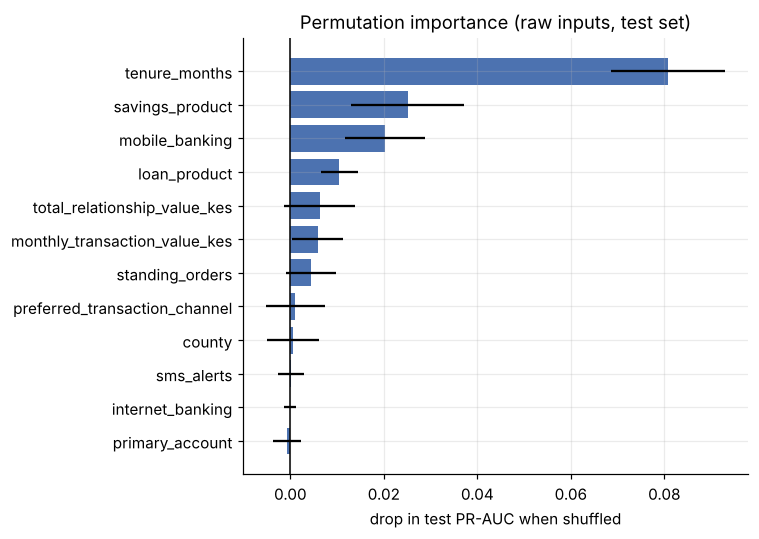

,mean,sd
tenure_months,0.081,0.012
savings_product,0.025,0.012
mobile_banking,0.020,0.009
loan_product,0.011,0.004
total_relationship_value_kes,0.006,0.008
monthly_transaction_value_kes,0.006,0.005
standing_orders,0.004,0.005
preferred_transaction_channel,0.001,0.006


In [44]:
# 10a. Permutation importance on the HOLD-OUT (drop in PR-AUC when a raw input is shuffled)
from sklearn.inspection import permutation_importance

perm = permutation_importance(final_model, X_test, y_test, scoring="average_precision",
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({"mean": perm.importances_mean, "sd": perm.importances_std}, index=X_test.columns) \
        .sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(7, 5))
top = imp.head(12).iloc[::-1]
ax.barh(top.index, top["mean"], xerr=top["sd"], color="#4C72B0")
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("drop in test PR-AUC when shuffled")
ax.set_title("Permutation importance (raw inputs, test set)")
plt.tight_layout()
plt.show()
imp.head(8).round(4)

### Decision-layer findings

At a maximum contact capacity of 140 customers, risk ranking reached
36 of 99 churners (36.4% recall and 25.7% precision). Value ranking reached
19 churners (19.2% recall and 13.6% precision).

Value ranking produced a higher model-expected net benefit under the
illustrative cost, save-rate and customer-value assumptions. These are
hypothetical estimates, not realised campaign savings. Calculations using
observed churn labels still assume an intervention effect that has not
been measured.

Risk ranking is the primary operational demonstration. Value ranking is
a secondary scenario requiring verified pre-decision customer values
and experimental evidence of retention effectiveness.

Risk bands describe score ranges derived from training predictions.
They are separate from the batch policy, which enforces a strict
contact limit.

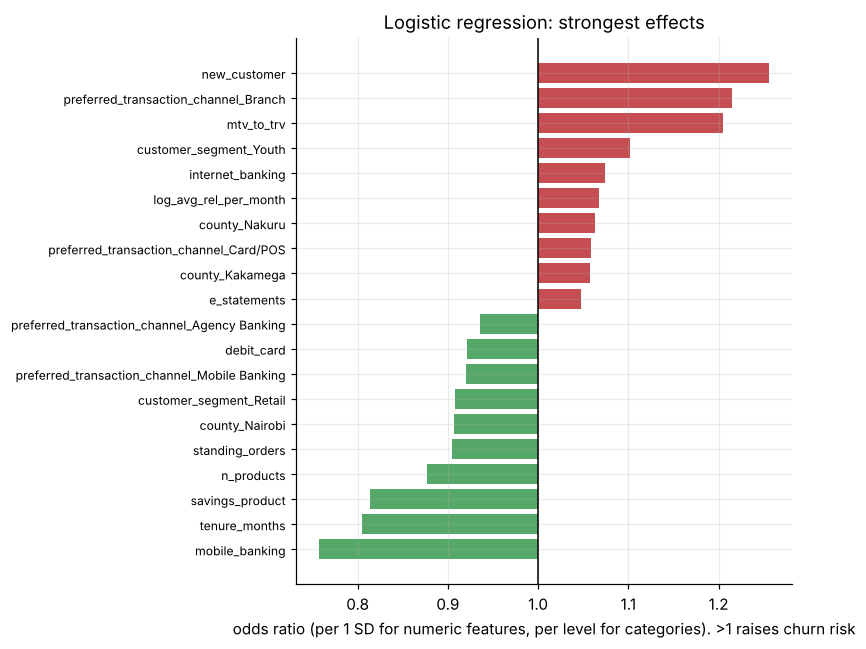

Lowest odds ratios (protective):
                 odds ratio
mobile_banking        0.757
tenure_months         0.804
savings_product       0.814
n_products            0.877
standing_orders       0.905
county_Nairobi        0.907

Highest odds ratios (risk-raising):
                                      odds ratio
new_customer                               1.256
preferred_transaction_channel_Branch       1.214
mtv_to_trv                                 1.205
customer_segment_Youth                     1.102
internet_banking                           1.074
log_avg_rel_per_month                      1.067


In [45]:
# 10b. Directional, auditable explanation from a plain logistic regression (odds ratios)
lr_explain = pipe_lr(C=lr_search.best_params_["clf__C"], class_weight="balanced").fit(X_train, y_train)
names = lr_explain.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr_explain.named_steps["clf"].coef_[0], index=names)
odds = pd.DataFrame({"coef": coefs, "odds ratio": np.exp(coefs)}).sort_values("coef")

fig, ax = plt.subplots(figsize=(7.4, 6))
sel = pd.concat([odds.head(10), odds.tail(10)])
ax.barh(sel.index, sel["odds ratio"] - 1, left=1, color=np.where(sel["odds ratio"] > 1, "#C44E52", "#55A868"))
ax.axvline(1, color="k", lw=1)
ax.set_xlabel("odds ratio (per 1 SD for numeric features, per level for categories). >1 raises churn risk")
ax.set_title("Logistic regression: strongest effects")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

print("Lowest odds ratios (protective):")
print(odds.head(6)[["odds ratio"]].round(3).to_string())
print("\nHighest odds ratios (risk-raising):")
print(odds.tail(6)[::-1][["odds ratio"]].round(3).to_string())

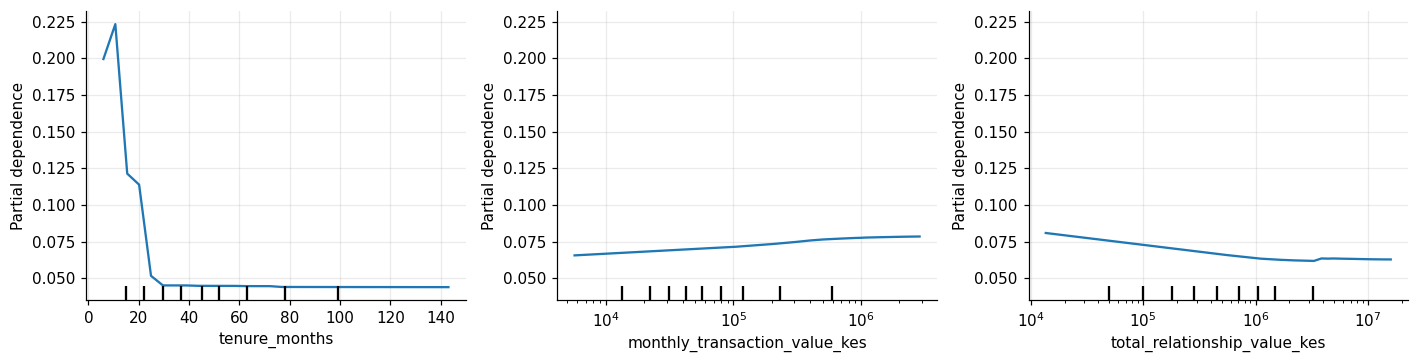

In [55]:
# 10c. Partial dependence of the final model on the main continuous drivers
from sklearn.inspection import PartialDependenceDisplay
try:
    # newer scikit-learn refuses integer columns in PDP; the pipeline accepts floats just as well
    X_pdp = X_train.copy()
    int_cols = X_pdp.select_dtypes(include="integer").columns
    X_pdp[int_cols] = X_pdp[int_cols].astype(float)
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
    PartialDependenceDisplay.from_estimator(final_model, X_pdp,
        ["tenure_months", "monthly_transaction_value_kes", "total_relationship_value_kes"],
        kind="average", grid_resolution=30, percentiles=(0.02, 0.98), ax=ax)
    for a in ax[1:]:
        a.set_xscale("log")
    plt.tight_layout()
    plt.show()
except Exception as e:                      # PDP API differs a little across scikit-learn versions
    plt.close("all")
    print("Partial dependence skipped:", type(e).__name__, e)

In [57]:
audit_df = test.assign(
    p=p_test,
    flagged=risk_contacts,
)

def group_audit(column):
    grouped_data = audit_df.copy()

    grouped_data[column] = (
        grouped_data[column]
        .astype("string")
        .fillna("(Missing)")
    )

    rows = []

    for level, group in grouped_data.groupby(
        column,
        observed=True,
        dropna=False,
    ):
        n = len(group)
        positives = int(group["churn"].sum())
        negatives = n - positives

        flagged_churners = int(
            (
                group["flagged"]
                & group["churn"].eq(1)
            ).sum()
        )

        flagged_nonchurners = int(
            (
                group["flagged"]
                & group["churn"].eq(0)
            ).sum()
        )

        rows.append({
            column: level,
            "customers": n,
            "churners": positives,
            "actual_rate": group["churn"].mean(),
            "average_predicted_risk": group["p"].mean(),
            "flag_rate": group["flagged"].mean(),
            "recall": (
                flagged_churners / positives
                if positives else np.nan
            ),
            "false_positive_rate": (
                flagged_nonchurners / negatives
                if negatives else np.nan
            ),
            "roc_auc": (
                roc_auc_score(group["churn"], group["p"])
                if positives >= 20 and negatives >= 20
                else np.nan
            ),
            "small_sample": positives < 20 or negatives < 20,
        })

    result = pd.DataFrame(rows).set_index(column)

    assert result["customers"].sum() == len(audit_df)
    assert result["churners"].sum() == audit_df["churn"].sum()

    return result


for column in ["gender", "age_band", "customer_segment"]:
    result = group_audit(column)

    print(f"\nAudit by {column}")
    display(result.round(3))

    result.to_csv(
        ARTIFACT_DIR / f"subgroup_audit_{column}.csv"
    )

print("All subgroup tables include every test customer.")


Audit by gender


,customers,churners,actual_rate,average_predicted_risk,flag_rate,recall,false_positive_rate,roc_auc,small_sample
gender,,,,,,,,,
Female,699,46,0.066,0.068,0.087,0.326,0.070,0.756,False
Male,698,53,0.076,0.073,0.110,0.396,0.087,0.770,False
Other/Not stated,12,0,0.000,0.078,0.167,NaN,0.167,NaN,True



Audit by age_band


,customers,churners,actual_rate,average_predicted_risk,flag_rate,recall,false_positive_rate,roc_auc,small_sample
age_band,,,,,,,,,
(Missing),19,1,0.053,0.072,0.158,1.000,0.111,NaN,True
18-24,130,7,0.054,0.073,0.092,0.571,0.065,NaN,True
25-34,414,28,0.068,0.066,0.087,0.286,0.073,0.710,False
35-44,375,27,0.072,0.066,0.091,0.444,0.063,0.787,False
45-54,228,17,0.075,0.074,0.118,0.235,0.109,NaN,True
55-64,155,14,0.090,0.081,0.142,0.429,0.113,NaN,True
65+,88,5,0.057,0.073,0.068,0.200,0.060,NaN,True



Audit by customer_segment


,customers,churners,actual_rate,average_predicted_risk,flag_rate,recall,false_positive_rate,roc_auc,small_sample
customer_segment,,,,,,,,,
Corporate,71,9,0.127,0.064,0.070,0.222,0.048,NaN,True
Retail,855,51,0.060,0.069,0.094,0.373,0.076,0.800,False
SME,240,24,0.100,0.066,0.083,0.292,0.060,0.715,False
Sacco,67,5,0.075,0.071,0.119,0.600,0.081,NaN,True
Youth,176,10,0.057,0.084,0.153,0.500,0.133,NaN,True


All subgroup tables include every test customer.


In [59]:
from sklearn.inspection import permutation_importance

# Confirm the fitted model and test data are available.
required = ["final_model", "X_test", "y_test", "ARTIFACT_DIR"]
missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. "
        "Run the preceding setup and final-model cells first."
    )

# Measure the change in average precision when each raw input
# is shuffled. This does not retrain or change the fitted model.
perm = permutation_importance(
    estimator=final_model,
    X=X_test,
    y=y_test,
    scoring="average_precision",
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

imp = (
    pd.DataFrame(
        {
            "mean": perm.importances_mean,
            "sd": perm.importances_std,
        },
        index=X_test.columns,
    )
    .sort_values("mean", ascending=False)
)

imp.index.name = "feature"

output_path = ARTIFACT_DIR / "permutation_importance.csv"
imp.to_csv(output_path)

display(imp.head(10).round(4))
print("Saved:", output_path)

,mean,sd
feature,,
tenure_months,0.082,0.013
savings_product,0.018,0.011
mobile_banking,0.016,0.006
loan_product,0.007,0.004
monthly_transaction_value_kes,0.004,0.006
preferred_transaction_channel,0.003,0.003
standing_orders,0.001,0.004
primary_account,0.001,0.001
total_relationship_value_kes,0.001,0.009


Saved: c:\Users\Spectre\PROJECTS\kenya-bank-customer-churn\artifacts\permutation_importance.csv


### Subgroup findings and limitations

Under the strict-capacity risk policy, recall was 32.6% for women and
39.6% for men. These descriptive differences require uncertainty analysis
and evaluation on additional data; they do not establish discrimination
or its absence.

Youth customers had average predicted risk of 8.4%, compared with an
observed churn rate of 5.7%. Corporate and SME customers had observed
churn rates above their average predicted risks. These patterns suggest
possible subgroup probability-estimation differences, but several groups
contain very few churners.

Missing demographic values are reported as a separate group so that
the audit includes all test customers.

Gender and age are excluded from the final model inputs. Their exclusion
does not guarantee fairness because other variables may carry related
information. No subgroup-specific thresholds or model adjustments were
chosen from these test results.

In [60]:
import json

exact_parameters = {
    key.replace("clf__", "", 1): value
    for key, value in hgb_search.best_params_.items()
}

with open(
    ARTIFACT_DIR / "selected_hgb_params.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        exact_parameters,
        file,
        indent=2,
        default=lambda value: value.item(),
    )

print("Saved exact boosting parameters.")

Saved exact boosting parameters.
